# Người 2 — Lab K-means, contour và Canny

Notebook dùng hand crop 225×225 và chỉ phân loại crop; không huấn luyện detector. Bốn lớp có crop sẵn lấy từ MANUS-HaGRID V1: `thumbs_up`/`thumbs_down` được chuẩn hóa thành `like`/`dislike`, còn `stop` và `ok` giữ nguyên. MANUS-HaGRID V1 không có lớp `no_gesture`, nên lớp này được bổ sung từ ảnh và bbox train của HaGRID V2 upstream; mỗi bbox được crop vuông với margin 1.30× rồi resize về 225×225. HaGRID định nghĩa bbox chuẩn hóa theo thứ tự `[x, y, width, height]` ([tài liệu upstream](https://github.com/hukenovs/hagrid/blob/master/README.md)).

Subset cân bằng nằm trong `data/manus_hagrid/data/balanced_v1v2/{train,test}`: 1,046 ảnh mỗi lớp, 940 train + 106 held-out; notebook tách thêm 10% train làm validation. Bốn lớp gesture dùng crop MANUS V1, còn `no_gesture` dùng crop tạo từ bbox HaGRID V2, vì MANUS V1 test không có hand_rgb crop ([README MANUS-HaGRID](https://huggingface.co/datasets/QFun/MANUS-HaGRID/blob/main/README.md)). Do đó test ở notebook là held-out sample-level từ source train, không phải official test và năm lớp có nguồn phiên bản khác nhau.

Thí nghiệm gồm kiểm tra nhãn stop/ok, kiểm tra RGB/BGR, so sánh Median/Gaussian, phân đoạn Lab + K-means (K=2,3,4,5), morphology, contour, đặc trưng Hu/hình học và SVM; C/gamma được chọn bằng validation. Nhánh Canny tập trung vào closing, lọc connected components và tạo mask.

Mọi thuật toán thí nghiệm nằm trong notebook này; các module rỗng trong src không được sửa trong phần của Người 2.

In [1]:
from pathlib import Path
import io
import json
import re
import tarfile
from collections import Counter, defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, ConfusionMatrixDisplay,
)

SEED = 42
np.random.seed(SEED)
cv2.setNumThreads(1)

# Tự tìm thư mục gốc để notebook chạy từ repo hoặc experiments/.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc hand_gesture_project có src/.")

DATA_ROOT = PROJECT_ROOT / "data" / "manus_hagrid"
DATA_CONFIG = "balanced_v1v2"
TARGET_LABELS = ("like", "dislike", "stop", "ok", "no_gesture")
SOURCE_TO_PROJECT = {
    "like": "like", "dislike": "dislike", "stop": "stop", "ok": "ok",
    "no_gesture": "no_gesture",
}
MAX_TRAIN_PER_CLASS = 940
MAX_TEST_PER_CLASS = 106
VALIDATION_FRACTION = 0.10
WORK_SIZE = (96, 96)  # width, height cho K-means/đặc trưng
K_CANDIDATES = (2, 3, 4, 5)
FILTER_CANDIDATES = ("none", "median", "gaussian")
print("Project:", PROJECT_ROOT)
print("Dataset:", DATA_ROOT)
print("Config:", DATA_CONFIG)

Project: D:\CV\hand_gesture_project
Dataset: D:\CV\hand_gesture_project\data\manus_hagrid
Config: balanced_v1v2


In [2]:
def source_label_from_metadata(meta, sample_prefix):
    values = []
    for key in ("gesture_label", "gesture", "label", "class", "category",
                "sample_id", "manus_sample_id", "source_image_id"):
        value = meta.get(key)
        if isinstance(value, (str, int, float)):
            values.append(str(value).strip().lower())
        elif isinstance(value, (list, tuple)):
            values.extend(str(item).strip().lower() for item in value)
    values.append(str(sample_prefix).lower())

    for value in values:
        if value in TARGET_LABELS:
            return value
    for value in values:
        for label in sorted(TARGET_LABELS, key=len, reverse=True):
            if re.search(rf"(?<![a-z0-9]){re.escape(label)}(?![a-z0-9])", value):
                return label
    return None


def member_basename(name):
    return name.replace("\\", "/").rsplit("/", 1)[-1]


def tar_paths(split):
    folder = DATA_ROOT / "data" / DATA_CONFIG / split
    paths = sorted(folder.glob("*.tar"))
    if not paths:
        raise FileNotFoundError(
            f"Không thấy shard .tar tại {folder}. "
            "Đặt dữ liệu vào data/manus_hagrid/data/hagrid_v2/{train,test}/."
        )
    return paths


def load_balanced_split(split, cap_per_class):
    if split not in ("train", "test"):
        raise ValueError("split chỉ nhận train hoặc test.")
    rng = np.random.default_rng(SEED + (0 if split == "train" else 1))
    reservoirs = {label: [] for label in TARGET_LABELS}
    eligible = Counter()

    # Quét metadata/header; chỉ giải mã hand_rgb của mẫu được lấy.
    for tar_path in tar_paths(split):
        with tarfile.open(tar_path, mode="r:*") as archive:
            members = archive.getmembers()
            by_base = {member_basename(m.name): m for m in members}
            for meta_member in members:
                basename = member_basename(meta_member.name)
                if not basename.endswith(".json") or basename.count(".") != 1:
                    continue  # bỏ bbox.json, normal.json...
                prefix = basename[:-5]
                hand_member = by_base.get(prefix + ".hand_rgb.png")
                if hand_member is None:
                    continue
                handle = archive.extractfile(meta_member)
                if handle is None:
                    continue
                try:
                    meta = json.loads(handle.read().decode("utf-8"))
                except (UnicodeDecodeError, json.JSONDecodeError):
                    continue
                meta_split = str(meta.get("split", split)).lower().split("/")[-1]
                if meta_split != split:
                    continue
                label = source_label_from_metadata(meta, prefix)
                if label not in TARGET_LABELS:
                    continue

                eligible[label] += 1
                record = {
                    "sample_id": str(meta.get("sample_id", meta.get("manus_sample_id", prefix))),
                    "source_image_id": meta.get("source_image_id"),
                    "source_label": label,
                    "project_label": SOURCE_TO_PROJECT[label],
                    "split": split,
                    "shard_path": str(tar_path),
                    "hand_member_name": hand_member.name,
                }
                bucket = reservoirs[label]
                seen = eligible[label]
                if len(bucket) < cap_per_class:
                    bucket.append(record)
                else:
                    replacement = int(rng.integers(0, seen))
                    if replacement < cap_per_class:
                        bucket[replacement] = record

    # Cân bằng bằng cách giảm về lớp ít mẫu nhất; không oversampling.
    available = {label: len(reservoirs[label]) for label in TARGET_LABELS}
    count = min(available.values())
    if count == 0:
        raise ValueError(f"Không có hand_rgb cho đủ các lớp. Eligible: {dict(eligible)}")
    selected = []
    for label in TARGET_LABELS:
        selected.extend(sorted(reservoirs[label], key=lambda r: r["sample_id"])[:count])

    by_shard = defaultdict(list)
    for record in selected:
        by_shard[record["shard_path"]].append(record)

    decoded = []
    for shard_path, records in by_shard.items():
        with tarfile.open(shard_path, mode="r:*") as archive:
            by_base = {member_basename(m.name): m for m in archive.getmembers()}
            for record in records:
                member = by_base.get(member_basename(record["hand_member_name"]))
                if member is None:
                    continue
                handle = archive.extractfile(member)
                if handle is None:
                    continue
                try:
                    rgb = np.asarray(Image.open(io.BytesIO(handle.read())).convert("RGB"))
                except Exception:
                    continue
                if rgb.ndim == 3 and rgb.shape[2] == 3:
                    item = dict(record)
                    item["image_rgb"] = rgb
                    decoded.append(item)

    decoded_by_label = {
        label: sorted([r for r in decoded if r["source_label"] == label],
                      key=lambda r: r["sample_id"])
        for label in TARGET_LABELS
    }
    final_count = min(len(decoded_by_label[label]) for label in TARGET_LABELS)
    balanced = [
        record
        for label in TARGET_LABELS
        for record in decoded_by_label[label][:final_count]
    ]
    return balanced, {
        "eligible_with_hand_rgb": dict(eligible),
        "loaded_balanced_per_class": final_count,
    }


def counts(records):
    return Counter(record["source_label"] for record in records)

In [3]:
train_records, train_scan = load_balanced_split("train", MAX_TRAIN_PER_CLASS)
test_records, test_scan = load_balanced_split("test", MAX_TEST_PER_CLASS)

train_labels = [r["source_label"] for r in train_records]
train_idx, val_idx = train_test_split(
    np.arange(len(train_records)), test_size=VALIDATION_FRACTION,
    random_state=SEED, stratify=train_labels,
)
train_fit_records = [train_records[i] for i in train_idx]
val_records = [train_records[i] for i in val_idx]

train_ids = {r["sample_id"] for r in train_fit_records}
val_ids = {r["sample_id"] for r in val_records}
test_ids = {r["sample_id"] for r in test_records}
assert train_ids.isdisjoint(val_ids | test_ids)
assert val_ids.isdisjoint(test_ids)

audit = pd.DataFrame([
    {
        "source_label": label,
        "project_label": SOURCE_TO_PROJECT[label],
        "train_subset_available": train_scan["eligible_with_hand_rgb"].get(label, 0),
        "train_loaded": counts(train_records).get(label, 0),
        "train_fit": counts(train_fit_records).get(label, 0),
        "validation": counts(val_records).get(label, 0),
        "test_subset_available": test_scan["eligible_with_hand_rgb"].get(label, 0),
        "test_loaded": counts(test_records).get(label, 0),
    }
    for label in TARGET_LABELS
])
display(audit)
print("Kiểm tra nhãn stop và ok:")
display(audit[audit["source_label"].isin(["stop", "ok"])])
print("Train và held-out được lấy sample-level từ source train; validation tách stratified 10% từ train.")
print("Bốn lớp gesture dùng MANUS V1; no_gesture dùng bbox crop từ HaGRID V2 upstream. Đây không phải official test.")
print("Test không dùng để chọn filter, K hoặc ngưỡng.")

,source_label,project_label,train_subset_available,train_loaded,train_fit,validation,test_subset_available,test_loaded
0,like,like,940,940,846,94,106,106
1,dislike,dislike,940,940,846,94,106,106
2,stop,stop,940,940,846,94,106,106
3,ok,ok,940,940,846,94,106,106
4,no_gesture,no_gesture,940,940,846,94,106,106


Kiểm tra nhãn stop và ok:


,source_label,project_label,train_subset_available,train_loaded,train_fit,validation,test_subset_available,test_loaded
2,stop,stop,940,940,846,94,106,106
3,ok,ok,940,940,846,94,106,106


Train và held-out được lấy sample-level từ source train; validation tách stratified 10% từ train.
Bốn lớp gesture dùng MANUS V1; no_gesture dùng bbox crop từ HaGRID V2 upstream. Đây không phải official test.
Test không dùng để chọn filter, K hoặc ngưỡng.


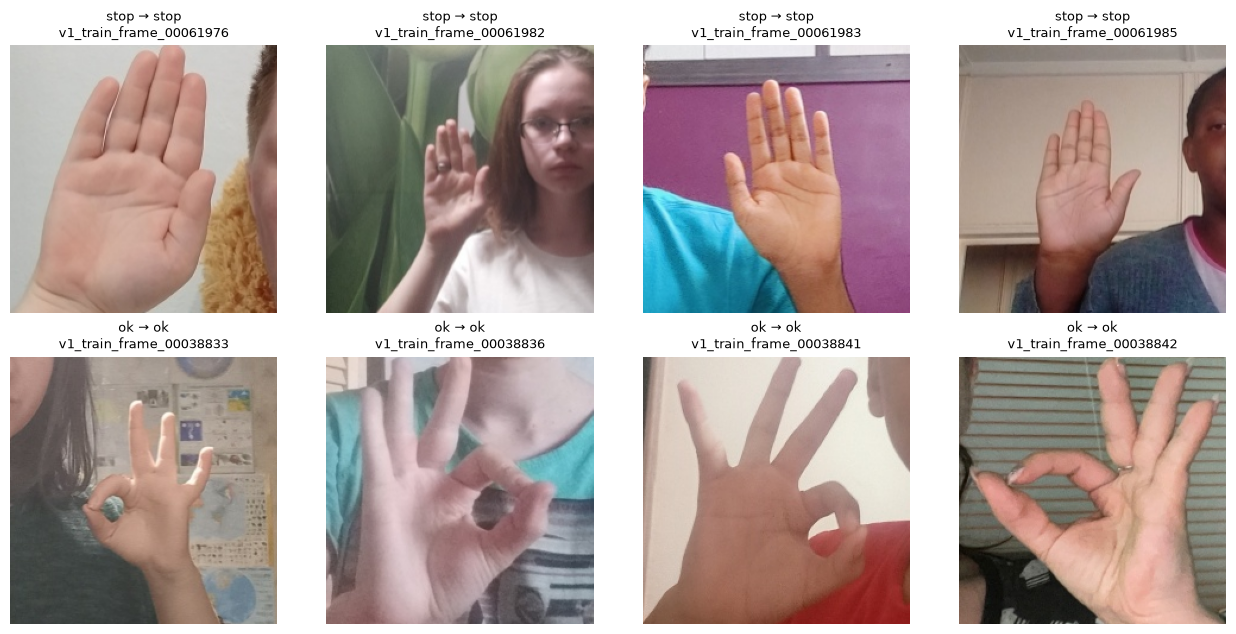

In [4]:
def show_examples(records, labels=("stop", "ok"), per_label=4):
    chosen = []
    for label in labels:
        chosen.extend([r for r in records if r["source_label"] == label][:per_label])
    if not chosen:
        print("Không tìm thấy mẫu cho nhãn được yêu cầu.")
        return
    cols = min(per_label, len(chosen))
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.2 * rows))
    axes = np.asarray(axes).reshape(-1)
    for ax, record in zip(axes, chosen):
        ax.imshow(record["image_rgb"])
        ax.set_title(
            f'{record["source_label"]} → {record["project_label"]}\n'
            f'{record["sample_id"][:28]}',
            fontsize=9,
        )
        ax.axis("off")
    for ax in axes[len(chosen):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_examples(train_records, labels=("stop", "ok"), per_label=4)

RGB→Lab bằng mã RGB == BGR→Lab bằng mã BGR: True
Mean absolute error khi dùng nhầm mã BGR: 7.51514732510288


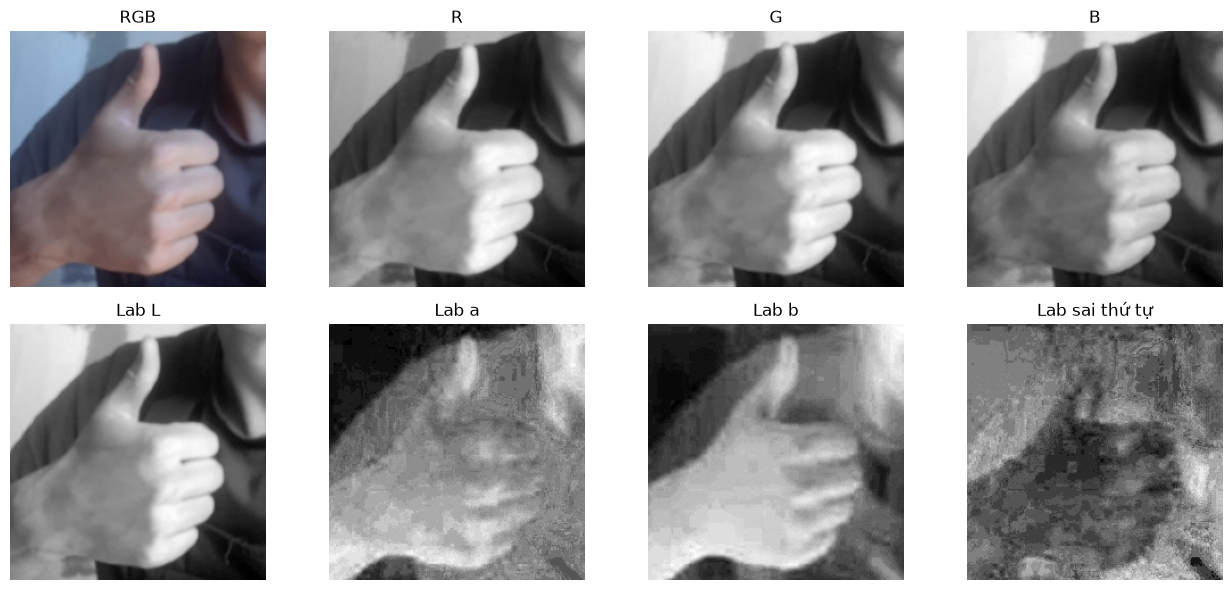

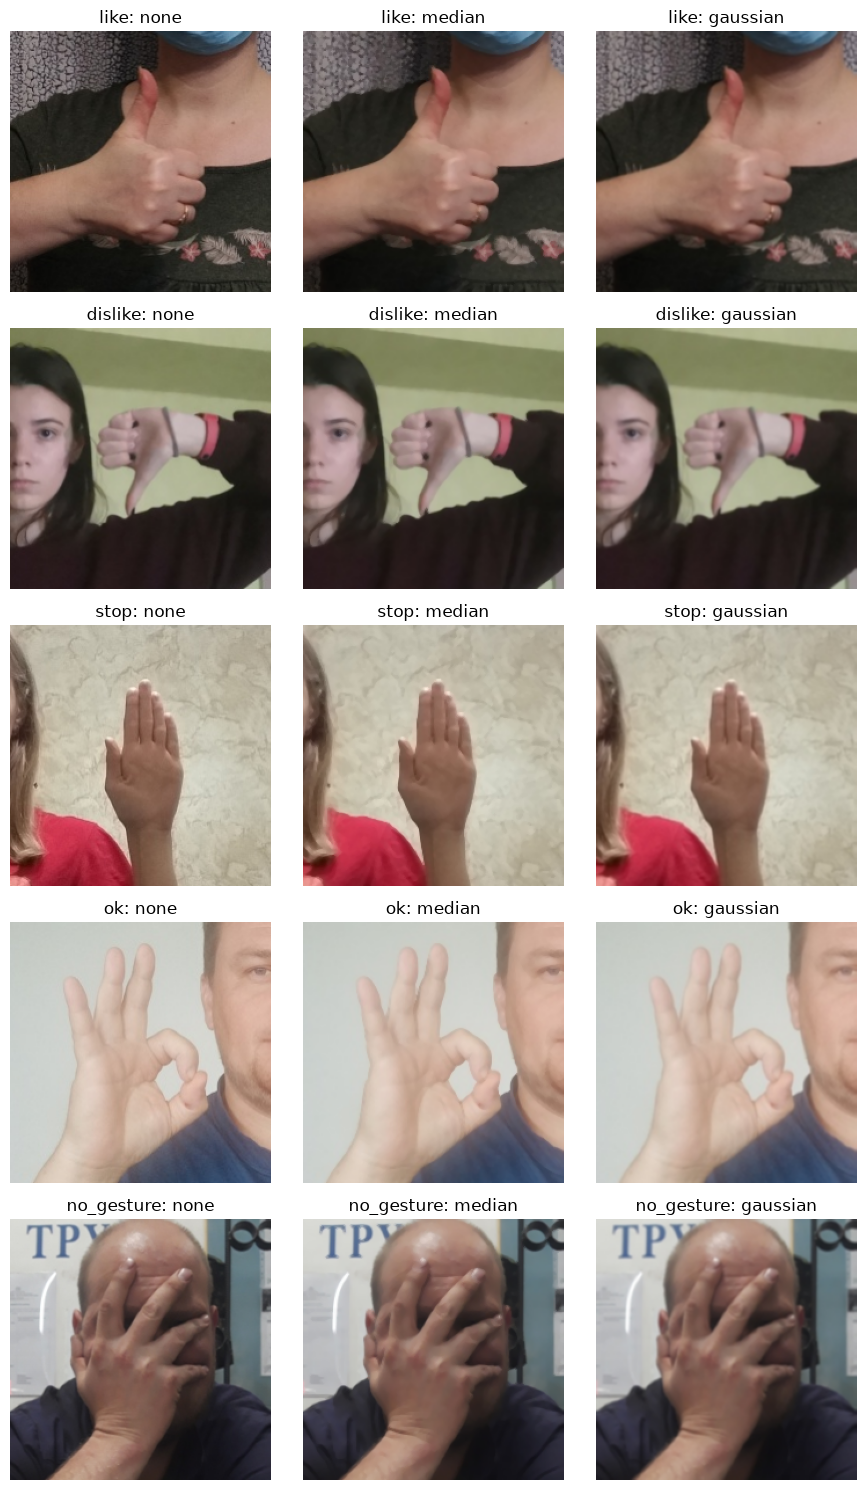

In [5]:
def filter_rgb(image_rgb, method="none", kernel_size=3):
    if method == "none":
        return image_rgb.copy()
    if method == "median":
        return cv2.medianBlur(image_rgb, kernel_size)
    if method == "gaussian":
        return cv2.GaussianBlur(image_rgb, (kernel_size, kernel_size), sigmaX=0)
    raise ValueError("method phải là none, median hoặc gaussian.")


# PIL đọc ảnh thành RGB. Hai cách đúng phải cho cùng kết quả Lab.
example_rgb = train_records[0]["image_rgb"]
example_bgr = cv2.cvtColor(example_rgb, cv2.COLOR_RGB2BGR)
lab_rgb = cv2.cvtColor(example_rgb, cv2.COLOR_RGB2LAB)
lab_bgr = cv2.cvtColor(example_bgr, cv2.COLOR_BGR2LAB)
lab_wrong = cv2.cvtColor(example_rgb, cv2.COLOR_BGR2LAB)
print("RGB→Lab bằng mã RGB == BGR→Lab bằng mã BGR:", np.array_equal(lab_rgb, lab_bgr))
print("Mean absolute error khi dùng nhầm mã BGR:",
      float(np.mean(np.abs(lab_rgb.astype(float) - lab_wrong.astype(float)))))

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
axes = axes.ravel()
for ax, plane, title in zip(
    axes,
    (example_rgb, example_rgb[:, :, 0], example_rgb[:, :, 1], example_rgb[:, :, 2],
     lab_rgb[:, :, 0], lab_rgb[:, :, 1], lab_rgb[:, :, 2], lab_wrong[:, :, 1]),
    ("RGB", "R", "G", "B", "Lab L", "Lab a", "Lab b", "Lab sai thứ tự"),
):
    ax.imshow(plane, cmap=None if plane.ndim == 3 else "gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# So sánh ảnh gốc, Median 3x3 và Gaussian 3x3 trên một mẫu train mỗi lớp.
preview = [
    next(r for r in train_fit_records if r["source_label"] == label)
    for label in TARGET_LABELS
]
fig, axes = plt.subplots(len(preview), 3, figsize=(9, 3 * len(preview)))
for row, record in enumerate(preview):
    for col, method in enumerate(("none", "median", "gaussian")):
        axes[row, col].imshow(filter_rgb(record["image_rgb"], method, 3))
        axes[row, col].set_title(f'{record["source_label"]}: {method}')
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [6]:
WORK_SIZE = (96, 96)

def estimate_reference_ab(records, filter_method):
    # Median Lab a,b của patch trung tâm; gom median qua train-fit.
    values = []
    for record in records:
        rgb = cv2.resize(
            filter_rgb(record["image_rgb"], filter_method, 3),
            WORK_SIZE, interpolation=cv2.INTER_AREA,
        )
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        h, w = lab.shape[:2]
        patch = lab[int(.42*h):int(.58*h), int(.42*w):int(.58*w), 1:3]
        values.append(np.median(patch.reshape(-1, 2), axis=0))
    return np.median(np.asarray(values, dtype=np.float32), axis=0)


def lab_kmeans_mask(image_rgb, k, reference_ab, filter_method="none"):
    rgb = cv2.resize(
        filter_rgb(image_rgb, filter_method, 3),
        WORK_SIZE, interpolation=cv2.INTER_AREA,
    )
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    pixels = lab.reshape(-1, 3).astype(np.float32)
    cv2.setRNGSeed(SEED + int(k))
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.5)
    _, labels, centers = cv2.kmeans(
        pixels, int(k), None, criteria, 1, cv2.KMEANS_PP_CENTERS
    )
    # Quy tắc cố định: cụm có a,b gần reference từ train nhất.
    distances = np.linalg.norm(
        centers[:, 1:3] - np.asarray(reference_ab, dtype=np.float32)[None, :],
        axis=1,
    )
    chosen = int(np.argmin(distances))
    raw = (labels.reshape(lab.shape[:2]) == chosen).astype(np.uint8) * 255
    open_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(raw, cv2.MORPH_OPEN, open_kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, close_kernel)

    count, component_labels, stats, _ = cv2.connectedComponentsWithStats(
        (mask > 0).astype(np.uint8), connectivity=8
    )
    clean = np.zeros_like(mask)
    min_area = max(8, int(0.001 * mask.size))
    kept = 0
    for component_id in range(1, count):
        if stats[component_id, cv2.CC_STAT_AREA] >= min_area:
            clean[component_labels == component_id] = 255
            kept += 1
    contours, _ = cv2.findContours(
        clean.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    contours = sorted(contours, key=cv2.contourArea, reverse=True)
    diag = {
        "foreground_ratio": float(np.mean(clean > 0)),
        "components_kept": kept,
        "contour_count": len(contours),
        "largest_contour_area": float(cv2.contourArea(contours[0])) if contours else 0.0,
    }
    return clean, contours, diag


REFERENCES = {
    method: estimate_reference_ab(train_fit_records, method)
    for method in ("none", "median", "gaussian")
}
display(pd.DataFrame([
    {"filter": name, "Lab_a_reference": float(value[0]), "Lab_b_reference": float(value[1])}
    for name, value in REFERENCES.items()
]))

,filter,Lab_a_reference,Lab_b_reference
0,none,141.0,139.0
1,median,141.0,139.0
2,gaussian,141.0,139.0


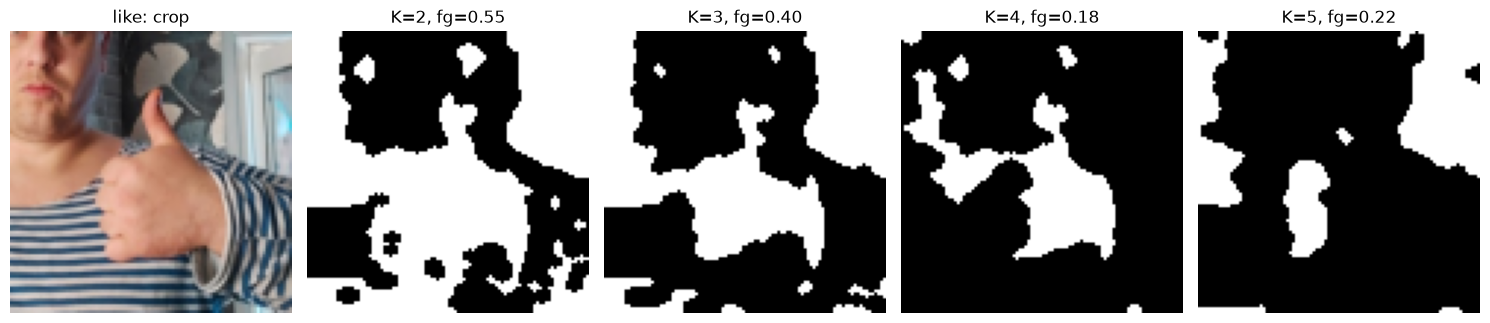

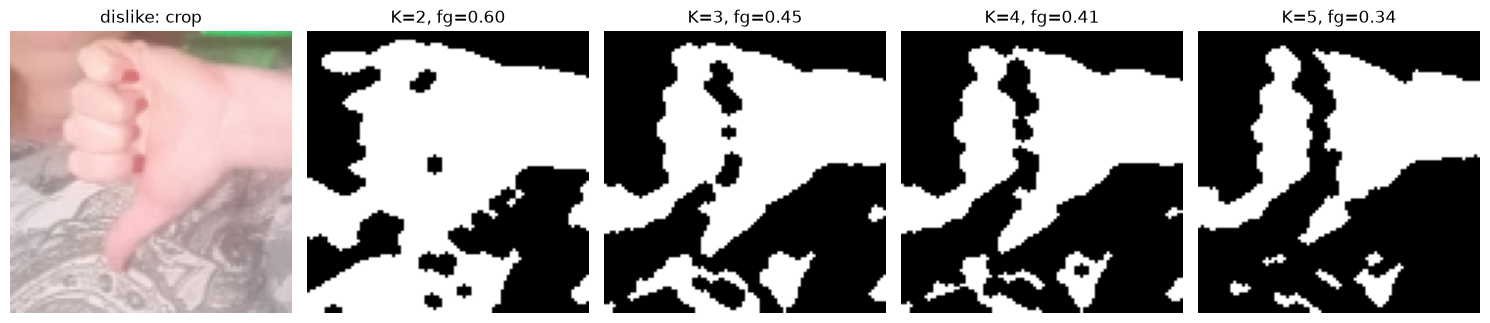

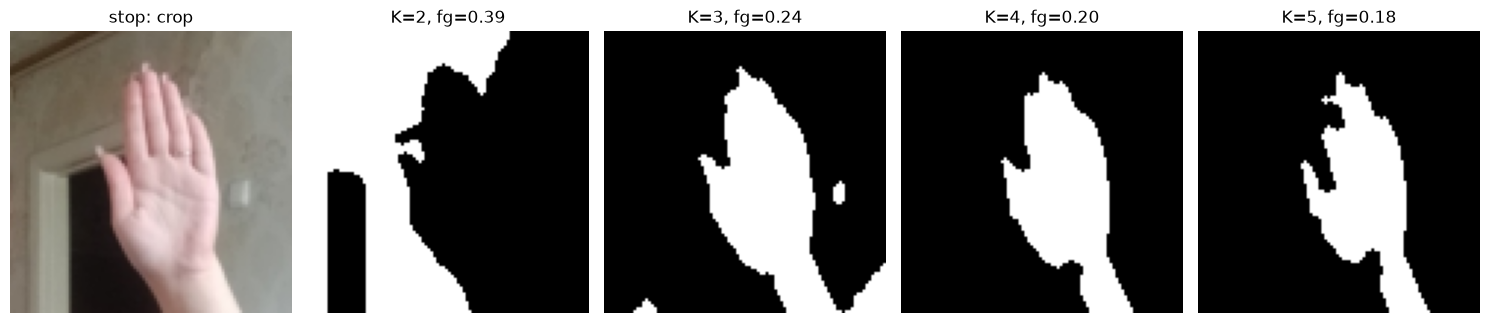

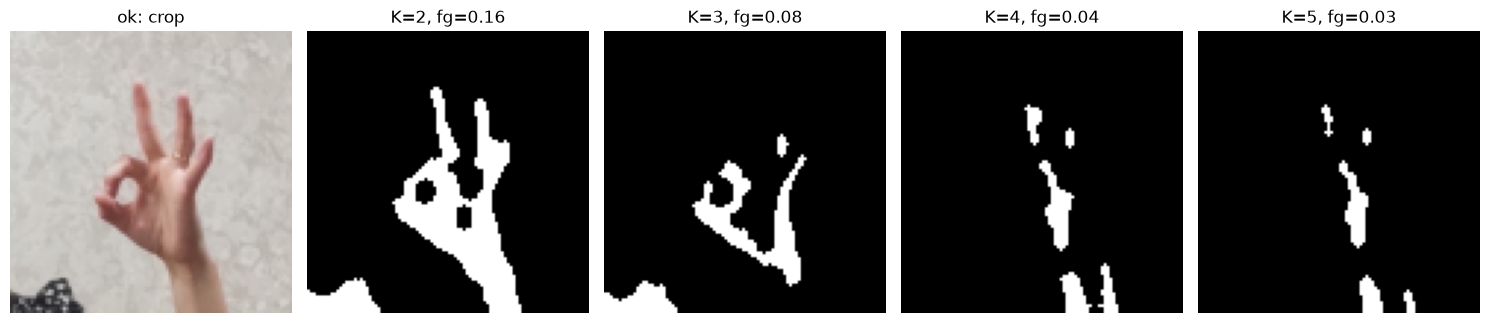

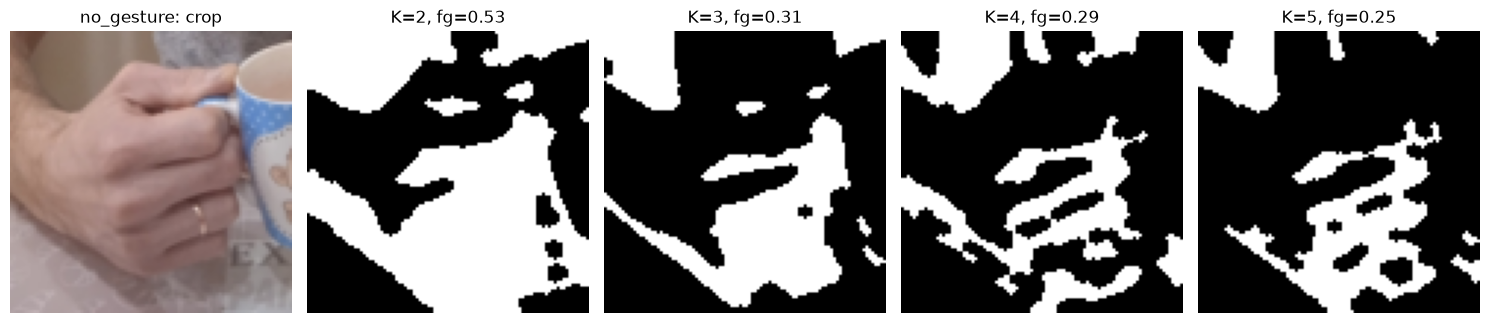

,filter,mean_foreground_ratio,mean_components,no_contour_rate
0,gaussian,0.338505,4.533333,0.0
1,median,0.337109,4.600000,0.0
2,none,0.302763,4.866667,0.0


In [7]:
# So sánh K=2,3,4,5 trên validation bằng cùng quy tắc chọn cluster.
def show_k_comparison(record, filter_method="none"):
    fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
    axes[0].imshow(cv2.resize(record["image_rgb"], WORK_SIZE, interpolation=cv2.INTER_AREA))
    axes[0].set_title(f'{record["source_label"]}: crop')
    axes[0].axis("off")
    for ax, k in zip(axes[1:], K_CANDIDATES):
        mask, contours, diag = lab_kmeans_mask(
            record["image_rgb"], k, REFERENCES[filter_method], filter_method
        )
        ax.imshow(mask, cmap="gray")
        ax.set_title(f'K={k}, fg={diag["foreground_ratio"]:.2f}')
        ax.axis("off")
    plt.tight_layout()
    plt.show()


for label in TARGET_LABELS:
    record = next((r for r in val_records if r["source_label"] == label), None)
    if record is not None:
        show_k_comparison(record)

# Median/Gaussian ảnh hưởng lên diện tích mask/components tại K=3.
# Đây là diagnostics không giám sát, không phải segmentation accuracy.
filter_probe_records = [
    record
    for label in TARGET_LABELS
    for record in [r for r in val_records if r["source_label"] == label][:3]
]
filter_rows = []
for record in filter_probe_records:
    for method in ("none", "median", "gaussian"):
        _, _, diag = lab_kmeans_mask(record["image_rgb"], 3, REFERENCES[method], method)
        filter_rows.append({"label": record["source_label"], "filter": method, **diag})
filter_diagnostics = pd.DataFrame(filter_rows)
display(
    filter_diagnostics.groupby("filter")
    .agg(
        mean_foreground_ratio=("foreground_ratio", "mean"),
        mean_components=("components_kept", "mean"),
        no_contour_rate=("contour_count", lambda x: float(np.mean(np.asarray(x) == 0))),
    )
    .reset_index()
)

In [8]:
def hu_shape_features(mask):
    contours, _ = cv2.findContours(
        (mask > 0).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        return np.zeros(13, dtype=np.float32), {
            "has_contour": False, "foreground_ratio": float(np.mean(mask > 0)),
            "components_kept": 0, "contour_area_ratio": 0.0,
        }

    contour = max(contours, key=cv2.contourArea)
    area = float(cv2.contourArea(contour))
    perimeter = float(cv2.arcLength(contour, True))
    x, y, width, height = cv2.boundingRect(contour)
    hull_area = float(cv2.contourArea(cv2.convexHull(contour)))
    image_area = float(mask.size)
    hu = cv2.HuMoments(cv2.moments(contour)).flatten()
    hu = np.clip(-np.sign(hu) * np.log10(np.abs(hu) + 1e-30), -20, 20)
    features = np.concatenate([
        hu,
        np.asarray([
            area / image_area,
            perimeter / max(np.hypot(*mask.shape), 1),
            width / max(height, 1),
            area / max(width * height, 1),
            area / max(hull_area, 1e-8),
            4 * np.pi * area / max(perimeter * perimeter, 1e-8),
        ]),
    ]).astype(np.float32)
    return features, {
        "has_contour": True,
        "foreground_ratio": float(np.mean(mask > 0)),
        "components_kept": int(cv2.connectedComponents(
            (mask > 0).astype(np.uint8), connectivity=8
        )[0] - 1),
        "contour_area_ratio": area / image_area,
    }


FEATURE_CACHE = {}

def feature_for_record(record, k, method, reference_ab):
    ref_key = tuple(np.round(reference_ab, 2).tolist())
    key = (record["split"], record["sample_id"], int(k), method, ref_key)
    if key not in FEATURE_CACHE:
        mask, contours, seg_diag = lab_kmeans_mask(
            record["image_rgb"], k, reference_ab, method
        )
        feature, shape_diag = hu_shape_features(mask)
        FEATURE_CACHE[key] = (feature, {**seg_diag, **shape_diag})
    return FEATURE_CACHE[key]


def feature_matrix(records, k, method, reference_ab):
    values, diagnostics = [], []
    for record in records:
        feature, diag = feature_for_record(record, k, method, reference_ab)
        values.append(feature)
        diagnostics.append(diag)
    return np.vstack(values), pd.DataFrame(diagnostics)


def make_svm(c=10.0, gamma="scale"):
    return Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC(
            kernel="rbf", C=float(c), gamma=gamma,
            class_weight="balanced", random_state=SEED,
        )),
    ])

In [9]:
# Chọn filter bằng validation tại K=3, sau đó chọn K bằng validation.
# Test chưa được dùng để chọn tham số.
y_train_fit = np.asarray([r["source_label"] for r in train_fit_records])
y_val = np.asarray([r["source_label"] for r in val_records])

filter_rows = []
for method in ("none", "median", "gaussian"):
    x_train, _ = feature_matrix(train_fit_records, 3, method, REFERENCES[method])
    x_val, _ = feature_matrix(val_records, 3, method, REFERENCES[method])
    model = make_svm()
    model.fit(x_train, y_train_fit)
    pred = model.predict(x_val)
    filter_rows.append({
        "filter": method, "K": 3,
        "validation_accuracy": accuracy_score(y_val, pred),
        "validation_macro_f1": f1_score(y_val, pred, average="macro"),
    })
filter_results = pd.DataFrame(filter_rows).sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False
).reset_index(drop=True)
display(filter_results)
selected_filter = str(filter_results.iloc[0]["filter"])

k_rows = []
for k in K_CANDIDATES:
    x_train, _ = feature_matrix(
        train_fit_records, k, selected_filter, REFERENCES[selected_filter]
    )
    x_val, _ = feature_matrix(
        val_records, k, selected_filter, REFERENCES[selected_filter]
    )
    model = make_svm()
    model.fit(x_train, y_train_fit)
    pred = model.predict(x_val)
    k_rows.append({
        "filter": selected_filter, "K": int(k),
        "validation_accuracy": accuracy_score(y_val, pred),
        "validation_macro_f1": f1_score(y_val, pred, average="macro"),
    })
k_results = pd.DataFrame(k_rows).sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False
).reset_index(drop=True)
display(k_results)
selected_k = int(k_results.iloc[0]["K"])
# Dò C/gamma trên validation với feature đã cố định; test không tham gia chọn mô hình.
x_train_selected, _ = feature_matrix(
    train_fit_records, selected_k, selected_filter, REFERENCES[selected_filter]
)
x_val_selected, _ = feature_matrix(
    val_records, selected_k, selected_filter, REFERENCES[selected_filter]
)
svm_rows = []
for c_value in (0.1, 1.0, 10.0, 100.0):
    for gamma_value in ("scale", 0.01, 0.03, 0.1, 0.3, 1.0):
        candidate = make_svm(c=c_value, gamma=gamma_value)
        candidate.fit(x_train_selected, y_train_fit)
        prediction = candidate.predict(x_val_selected)
        svm_rows.append({
            "C": c_value, "gamma": gamma_value,
            "validation_accuracy": accuracy_score(y_val, prediction),
            "validation_macro_f1": f1_score(y_val, prediction, average="macro"),
        })
svm_results = pd.DataFrame(svm_rows).sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False
).reset_index(drop=True)
display(svm_results.head(10))
selected_C = float(svm_results.iloc[0]["C"])
selected_gamma = svm_results.iloc[0]["gamma"]
print(
    f"Validation chọn filter={selected_filter}, K={selected_k}, "
    f"C={selected_C}, gamma={selected_gamma}."
)

,filter,K,validation_accuracy,validation_macro_f1
0,gaussian,3,0.417021,0.416838
1,none,3,0.400000,0.399247
2,median,3,0.378723,0.377169


,filter,K,validation_accuracy,validation_macro_f1
0,gaussian,3,0.417021,0.416838
1,gaussian,2,0.410638,0.411049
2,gaussian,4,0.389362,0.386945
3,gaussian,5,0.389362,0.383383


,C,gamma,validation_accuracy,validation_macro_f1
0,10.0,scale,0.417021,0.416838
1,10.0,0.1,0.410638,0.410814
2,100.0,0.01,0.408511,0.407624
3,10.0,0.03,0.402128,0.401553
4,1.0,0.3,0.402128,0.401452
5,100.0,scale,0.397872,0.397813
6,1.0,0.1,0.395745,0.395091
7,1.0,scale,0.395745,0.394559
8,100.0,0.03,0.393617,0.393714
9,1.0,0.03,0.387234,0.386184


Validation chọn filter=gaussian, K=3, C=10.0, gamma=scale.


Lab-K-means + morphology + Hu/shape + SVM | filter=gaussian, K=3, C=10.0, gamma=scale
Accuracy: 0.3679
Balanced accuracy: 0.3679
Macro-F1: 0.3662
              precision    recall  f1-score   support

        like       0.38      0.41      0.39       106
     dislike       0.36      0.41      0.38       106
        stop       0.41      0.41      0.41       106
          ok       0.36      0.36      0.36       106
  no_gesture       0.33      0.26      0.29       106

    accuracy                           0.37       530
   macro avg       0.37      0.37      0.37       530
weighted avg       0.37      0.37      0.37       530

Confusion matrix (rows=true, columns=predicted):


,like,dislike,stop,ok,no_gesture
like,43,25,17,8,13
dislike,24,43,15,11,13
stop,12,13,43,25,13
ok,15,16,19,38,18
no_gesture,18,24,11,25,28


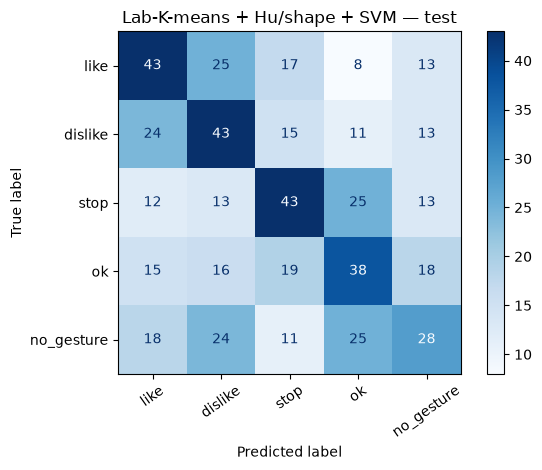

,true,predicted,count
0,like,dislike,25
10,stop,ok,25
19,no_gesture,ok,25
17,no_gesture,dislike,24
4,dislike,like,24
14,ok,stop,19
16,no_gesture,like,18
15,ok,no_gesture,18
1,like,stop,17
13,ok,dislike,16


In [10]:
# Fit model cuối trên train+validation; reference màu chỉ học từ train.
final_reference = estimate_reference_ab(train_records, selected_filter)
x_development, _ = feature_matrix(
    train_records, selected_k, selected_filter, final_reference
)
x_test, test_diag = feature_matrix(
    test_records, selected_k, selected_filter, final_reference
)
y_development = np.asarray([r["source_label"] for r in train_records])
y_test = np.asarray([r["source_label"] for r in test_records])

final_model = make_svm(c=selected_C, gamma=selected_gamma)
final_model.fit(x_development, y_development)
test_prediction = final_model.predict(x_test)

print(f"Lab-K-means + morphology + Hu/shape + SVM | filter={selected_filter}, K={selected_k}, C={selected_C}, gamma={selected_gamma}")
print("Accuracy:", round(accuracy_score(y_test, test_prediction), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, test_prediction), 4))
print("Macro-F1:", round(f1_score(y_test, test_prediction, average="macro"), 4))
print(classification_report(y_test, test_prediction, labels=TARGET_LABELS, zero_division=0))

cm = confusion_matrix(y_test, test_prediction, labels=TARGET_LABELS)
print("Confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(cm, index=TARGET_LABELS, columns=TARGET_LABELS))
ConfusionMatrixDisplay(cm, display_labels=TARGET_LABELS).plot(
    cmap="Blues", xticks_rotation=35, values_format="d"
)
plt.title("Lab-K-means + Hu/shape + SVM — test")
plt.tight_layout()
plt.show()

pairs = [
    {"true": TARGET_LABELS[i], "predicted": TARGET_LABELS[j], "count": int(cm[i, j])}
    for i in range(len(TARGET_LABELS))
    for j in range(len(TARGET_LABELS))
    if i != j and cm[i, j] > 0
]
if pairs:
    display(pd.DataFrame(pairs).sort_values("count", ascending=False).head(10))
else:
    print("Không có nhầm lẫn trong test subset hiện tại.")

,sample_id,true,predicted,foreground_ratio,components,mask_note
0,v1_train_frame_00026250,like,stop,0.241211,3,kiểm tra contour/nhầm cử chỉ
1,v1_train_frame_00026267,like,dislike,0.290582,8,kiểm tra contour/nhầm cử chỉ
2,v1_train_frame_00026276,like,dislike,0.439670,7,kiểm tra contour/nhầm cử chỉ
3,v1_train_frame_00026302,like,no_gesture,0.448893,3,kiểm tra contour/nhầm cử chỉ
4,v1_train_frame_00026354,like,no_gesture,0.398220,3,kiểm tra contour/nhầm cử chỉ
5,v1_train_frame_00026355,like,dislike,0.260851,2,kiểm tra contour/nhầm cử chỉ
6,v1_train_frame_00026370,like,dislike,0.573025,3,kiểm tra contour/nhầm cử chỉ
7,v1_train_frame_00026463,like,dislike,0.334418,4,kiểm tra contour/nhầm cử chỉ
8,v1_train_frame_00026530,like,no_gesture,0.441298,1,kiểm tra contour/nhầm cử chỉ
9,v1_train_frame_00026531,like,dislike,0.485569,6,kiểm tra contour/nhầm cử chỉ


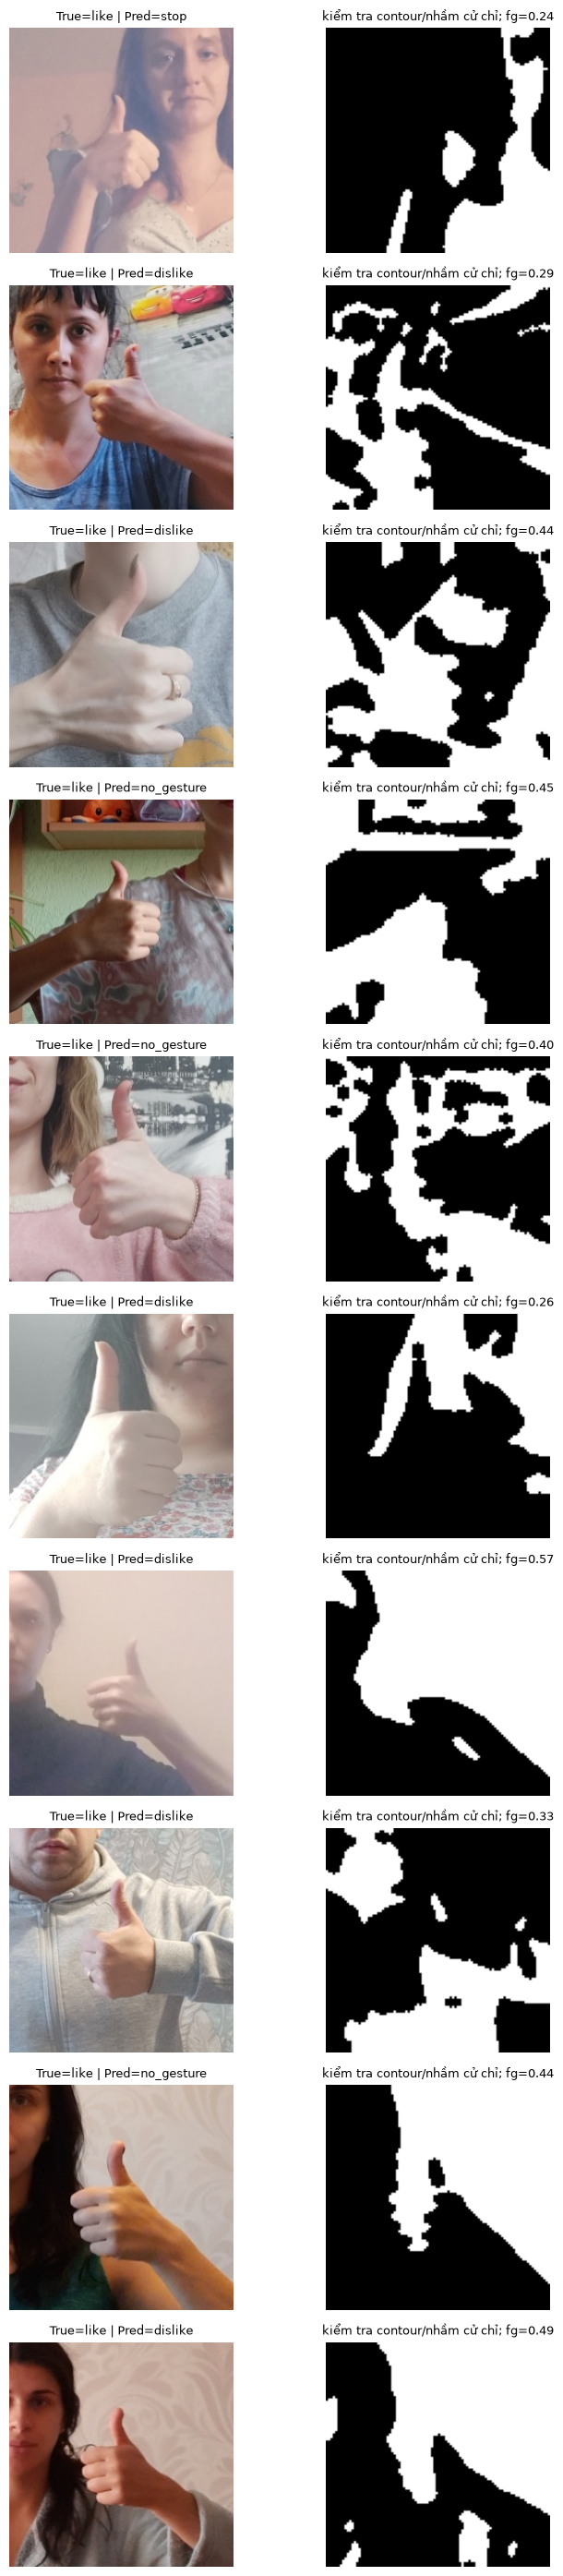

In [11]:
# Phân tích lỗi Lab: xem crop/mask và chỉ báo foreground/component.
# Các trạng thái mask là heuristic để xem ảnh, không thay cho pixel-level GT.
error_rows = []
for index, (record, predicted) in enumerate(zip(test_records, test_prediction)):
    if predicted == record["source_label"]:
        continue
    diag = test_diag.iloc[index].to_dict()
    ratio = float(diag.get("foreground_ratio", 0))
    if not diag.get("has_contour", False):
        note = "không có contour"
    elif ratio < 0.03:
        note = "mask rất nhỏ; có thể bỏ sót tay"
    elif ratio > 0.85:
        note = "mask phủ gần toàn crop"
    else:
        note = "kiểm tra contour/nhầm cử chỉ"
    error_rows.append({
        "sample_id": record["sample_id"], "true": record["source_label"],
        "predicted": predicted, "foreground_ratio": ratio,
        "components": int(diag.get("components_kept", 0)), "mask_note": note,
    })

errors = pd.DataFrame(error_rows)
if errors.empty:
    print("Không có mẫu sai trong test subset hiện tại.")
else:
    display(errors.head(20))
    n_show = min(10, len(errors))
    fig, axes = plt.subplots(n_show, 2, figsize=(8, 2.8 * n_show))
    if n_show == 1:
        axes = np.asarray([axes])
    by_id = {r["sample_id"]: r for r in test_records}
    for row, item in enumerate(errors.head(n_show).to_dict("records")):
        record = by_id[item["sample_id"]]
        mask, _, diag = lab_kmeans_mask(
            record["image_rgb"], selected_k, final_reference, selected_filter
        )
        axes[row, 0].imshow(record["image_rgb"])
        axes[row, 0].set_title(f'True={item["true"]} | Pred={item["predicted"]}', fontsize=9)
        axes[row, 1].imshow(mask, cmap="gray")
        axes[row, 1].set_title(f'{item["mask_note"]}; fg={diag["foreground_ratio"]:.2f}', fontsize=9)
        axes[row, 0].axis("off")
        axes[row, 1].axis("off")
    plt.tight_layout()
    plt.show()

In [12]:
def canny_to_mask(image_rgb, low_threshold=80, high_threshold=160,
                  close_kernel=5, min_edge_component=15, min_contour_area=20):
    rgb = cv2.resize(image_rgb, WORK_SIZE, interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), sigmaX=0)
    edges = cv2.Canny(gray, low_threshold, high_threshold, L2gradient=True)
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (close_kernel, close_kernel)
    )
    linked = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel, iterations=1)

    n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        (linked > 0).astype(np.uint8), connectivity=8
    )
    clean = np.zeros_like(linked)
    kept = 0
    for component_id in range(1, n_labels):
        if stats[component_id, cv2.CC_STAT_AREA] >= min_edge_component:
            clean[labels == component_id] = 255
            kept += 1

    contours, _ = cv2.findContours(
        clean.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    contours = [c for c in contours if cv2.contourArea(c) >= min_contour_area]
    contours.sort(key=cv2.contourArea, reverse=True)
    mask = np.zeros_like(gray)
    if contours:
        cv2.drawContours(mask, [contours[0]], -1, 255, cv2.FILLED)

    return {
        "gray": gray, "edges": edges, "linked": linked,
        "clean_edges": clean, "mask": mask, "contours": contours,
        "diagnostics": {
            "close_kernel": int(close_kernel),
            "edge_components_kept": int(kept),
            "contours_kept": len(contours),
            "mask_foreground_ratio": float(np.mean(mask > 0)),
        },
    }

,close_kernel,mean_components,mean_contours,mean_mask_ratio
0,3,4.2,2.6,0.109310
1,5,3.2,2.0,0.144184
2,7,2.4,1.8,0.197743


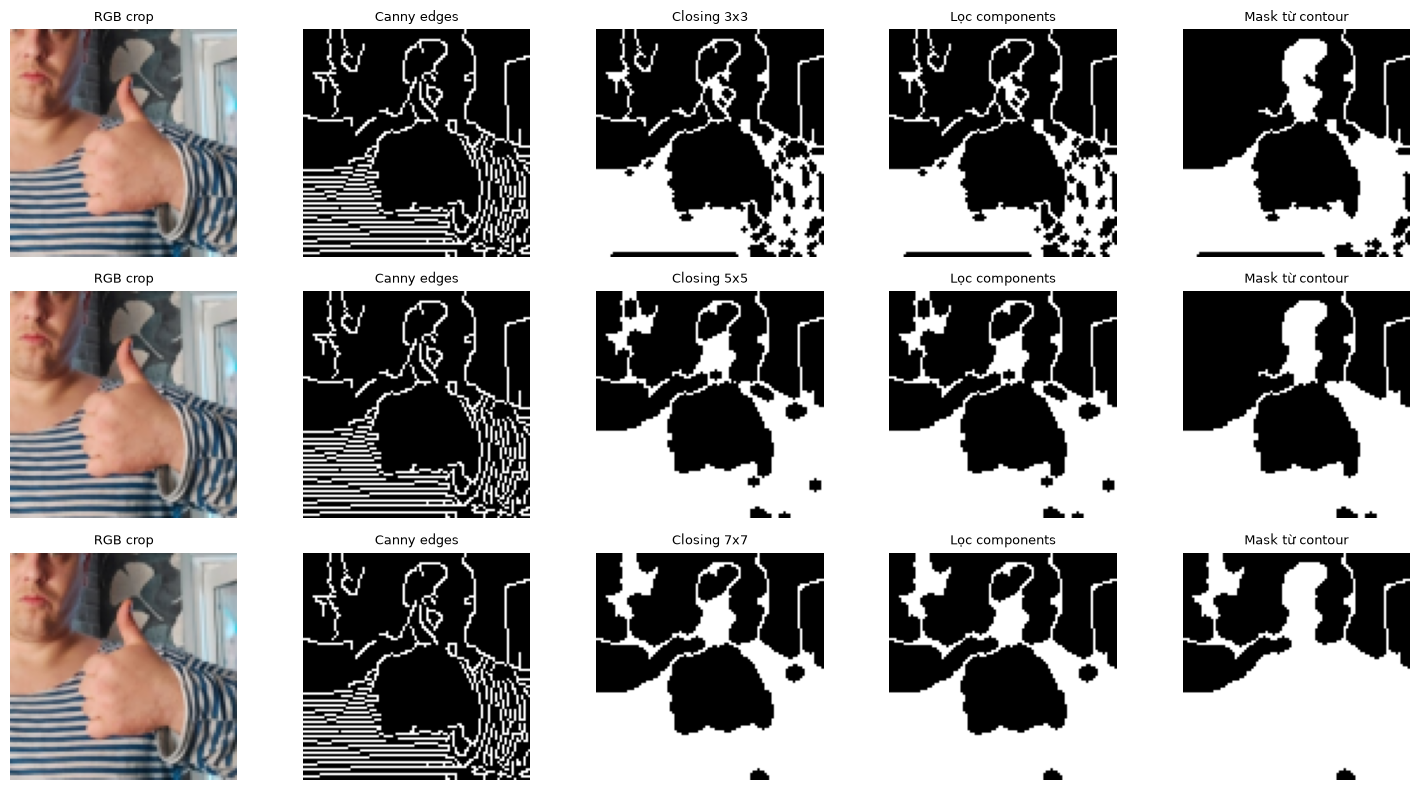

In [13]:
# Ngưỡng Canny cố định để tập trung vào phần Người 2:
# so sánh closing, lọc connected components và tạo mask.
representatives = [
    next(r for r in val_records if r["source_label"] == label)
    for label in TARGET_LABELS
]
canny_rows = []
for record in representatives:
    for kernel_size in (3, 5, 7):
        result = canny_to_mask(
            record["image_rgb"], close_kernel=kernel_size,
            min_edge_component=15, min_contour_area=20,
        )
        canny_rows.append({
            "label": record["source_label"],
            "sample_id": record["sample_id"],
            **result["diagnostics"],
        })
canny_summary = pd.DataFrame(canny_rows)
display(
    canny_summary.groupby("close_kernel")
    .agg(
        mean_components=("edge_components_kept", "mean"),
        mean_contours=("contours_kept", "mean"),
        mean_mask_ratio=("mask_foreground_ratio", "mean"),
    )
    .reset_index()
)

# Xem các bước cho cùng một crop validation với kernel 3,5,7.
record = representatives[0]
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for row, kernel_size in enumerate((3, 5, 7)):
    result = canny_to_mask(
        record["image_rgb"], close_kernel=kernel_size,
        min_edge_component=15, min_contour_area=20,
    )
    panels = (
        (cv2.resize(record["image_rgb"], WORK_SIZE, interpolation=cv2.INTER_AREA), "RGB crop"),
        (result["edges"], "Canny edges"),
        (result["linked"], f"Closing {kernel_size}x{kernel_size}"),
        (result["clean_edges"], "Lọc components"),
        (result["mask"], "Mask từ contour"),
    )
    for ax, (image, title) in zip(axes[row], panels):
        ax.imshow(image, cmap="gray" if image.ndim == 2 else None)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

## So sánh baseline HOG trên cùng split

Baseline này dùng grayscale 96×96 → HOG (9 orientations, cell 8×8, block 2×2, L2-Hys) → StandardScaler → RBF-SVM. C=1, gamma=`scale`; validation và held-out dùng đúng các record đã tạo ở trên. Đây là phép so sánh trên crop, không phải đánh giá detector. Cần cài `scikit-image` để chạy cell này.

In [14]:
from skimage.feature import hog as skimage_hog



HOG_INPUT_SIZE = (96, 96)



def hog_descriptor(record):

    gray = cv2.cvtColor(record["image_rgb"], cv2.COLOR_RGB2GRAY)

    gray = cv2.resize(gray, HOG_INPUT_SIZE, interpolation=cv2.INTER_AREA)

    return skimage_hog(

        gray,

        orientations=9,

        pixels_per_cell=(8, 8),

        cells_per_block=(2, 2),

        block_norm="L2-Hys",

        transform_sqrt=True,

        feature_vector=True,

    ).astype(np.float32)



def hog_matrix(records):

    return np.vstack([hog_descriptor(record) for record in records])



x_hog_fit = hog_matrix(train_fit_records)

x_hog_val = hog_matrix(val_records)

x_hog_development = hog_matrix(train_records)

x_hog_test = hog_matrix(test_records)

y_development = np.asarray([r["source_label"] for r in train_records])



hog_model = Pipeline([

    ("scale", StandardScaler()),

    ("svm", SVC(

        kernel="rbf", C=1.0, gamma="scale",

        class_weight="balanced", random_state=SEED,

    )),

])

hog_model.fit(x_hog_fit, y_train_fit)

hog_val_prediction = hog_model.predict(x_hog_val)

print("HOG feature dimension:", x_hog_fit.shape[1])

print("HOG validation accuracy:", round(accuracy_score(y_val, hog_val_prediction), 4))

print("HOG validation Macro-F1:", round(f1_score(y_val, hog_val_prediction, average="macro"), 4))



# Refit on train + validation; held-out remains untouched until this final scoring.

hog_model.fit(x_hog_development, y_development)

hog_test_prediction = hog_model.predict(x_hog_test)

hog_accuracy = accuracy_score(y_test, hog_test_prediction)

hog_balanced_accuracy = balanced_accuracy_score(y_test, hog_test_prediction)

hog_macro_f1 = f1_score(y_test, hog_test_prediction, average="macro")

print("HOG held-out accuracy:", round(hog_accuracy, 4))

print("HOG held-out balanced accuracy:", round(hog_balanced_accuracy, 4))

print("HOG held-out Macro-F1:", round(hog_macro_f1, 4))

print(classification_report(y_test, hog_test_prediction, labels=TARGET_LABELS, zero_division=0))



hog_cm = confusion_matrix(y_test, hog_test_prediction, labels=TARGET_LABELS)

print("HOG confusion matrix (rows=true, columns=predicted):")

display(pd.DataFrame(hog_cm, index=TARGET_LABELS, columns=TARGET_LABELS))

comparison = pd.DataFrame([

    {

        "model": "Lab-K-means + Hu/shape + SVM",

        "validation_macro_f1": float(svm_results.iloc[0]["validation_macro_f1"]),

        "heldout_accuracy": accuracy_score(y_test, test_prediction),

        "heldout_macro_f1": f1_score(y_test, test_prediction, average="macro"),

    },

    {

        "model": "Grayscale HOG + RBF-SVM",

        "validation_macro_f1": f1_score(y_val, hog_val_prediction, average="macro"),

        "heldout_accuracy": hog_accuracy,

        "heldout_macro_f1": hog_macro_f1,

    },

])

display(comparison)

HOG feature dimension: 4356
HOG validation accuracy: 0.934
HOG validation Macro-F1: 0.9341


HOG held-out accuracy: 0.9585
HOG held-out balanced accuracy: 0.9585
HOG held-out Macro-F1: 0.9584
              precision    recall  f1-score   support

        like       0.98      0.92      0.95       106
     dislike       0.95      1.00      0.98       106
        stop       0.94      0.97      0.96       106
          ok       0.95      0.95      0.95       106
  no_gesture       0.96      0.94      0.95       106

    accuracy                           0.96       530
   macro avg       0.96      0.96      0.96       530
weighted avg       0.96      0.96      0.96       530

HOG confusion matrix (rows=true, columns=predicted):


,like,dislike,stop,ok,no_gesture
like,98,2,1,3,2
dislike,0,106,0,0,0
stop,0,2,103,1,0
ok,0,0,3,101,2
no_gesture,2,1,2,1,100


,model,validation_macro_f1,heldout_accuracy,heldout_macro_f1
0,Lab-K-means + Hu/shape + SVM,0.416838,0.367925,0.366187
1,Grayscale HOG + RBF-SVM,0.934088,0.958491,0.958353


## Ghi nhận trước khi nộp



Sau khi chạy notebook với subset cân bằng local, lưu lại:

- Số mẫu dùng được từng lớp, đặc biệt stop, ok và no_gesture.

- Kiểm tra RGB/BGR; so sánh Median/Gaussian trên ảnh, mask và contour.

- Bảng validation chọn filter/K/C/gamma; Macro-F1, confusion matrix trên held-out subset.

- Các cặp lớp hay nhầm và ảnh lỗi Lab; xác định lỗi mask nhỏ, mask quá lớn, hoặc contour hợp lý nhưng Hu/shape chưa phân biệt được cử chỉ.

- Nhánh Canny: kernel closing nào nối khe hữu ích và khi nào closing nhập biên hoặc làm mask sai.



Subset có 1,046 mẫu mỗi lớp: `like`, `dislike`, `stop`, `ok` lấy từ crop MANUS-HaGRID V1; `no_gesture` lấy từ upstream HaGRID V2 train, crop bằng bbox annotation với margin 1.30×. Vì V1 test thiếu hand_rgb crop, held-out được tách từ source train theo sample; kết quả không phải official test và nguồn ảnh năm lớp không hoàn toàn đồng nhất. Nếu không có pixel-level segmentation mask, không báo IoU/Dice. Component/diện tích chỉ là chẩn đoán trực quan. Kết quả đánh giá phân loại trên hand crops, không đại diện cho detection trên ảnh toàn cảnh.

## Nhánh 2 mở rộng: Lab segmentation + HOG + Hu/shape

Có thể mở rộng nhánh 2 theo luồng: RGB crop → Lab K-means + morphology → mask tay → grayscale có mask → HOG; ghép descriptor HOG với 13 đặc trưng Hu/hình học → StandardScaler → RBF-SVM. HOG bổ sung phân bố hướng cạnh; Hu/shape giữ đặc trưng toàn cục của contour. Đây vẫn là nhánh segmentation Lab, khác với baseline HOG tính trực tiếp trên crop gốc.

Cell tiếp theo chọn C/gamma trên validation, sau đó fit lại train+validation và chỉ cuối cùng chấm held-out. So sánh gồm Lab shape hiện tại, HOG trên crop gốc và Lab-mask HOG + Hu/shape. Các tham số filter/K đã chọn trước ở nhánh Lab; test không được dùng để chọn mô hình.

Lưới SVM của nhánh mở rộng gồm 4 cặp C/gamma để giới hạn thời gian chạy; tham số chỉ được chọn trên validation.


In [9]:
def lab_hog_shape_vector(record, k, method, reference_ab):
    mask, _, seg_diag = lab_kmeans_mask(
        record["image_rgb"], k, reference_ab, method
    )
    rgb = cv2.resize(
        filter_rgb(record["image_rgb"], method, 3),
        WORK_SIZE, interpolation=cv2.INTER_AREA,
    )
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    segmented_gray = cv2.bitwise_and(gray, gray, mask=mask)
    hog_descriptor = skimage_hog(
        segmented_gray,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        transform_sqrt=True,
        feature_vector=True,
    )
    shape_descriptor, shape_diag = hu_shape_features(mask)
    combined = np.concatenate([
        hog_descriptor.astype(np.float32),
        shape_descriptor.astype(np.float32),
    ])
    return combined, {**seg_diag, **shape_diag}


def lab_hog_shape_matrix(records, k, method, reference_ab):
    vectors, diagnostics = [], []
    for record in records:
        vector, diag = lab_hog_shape_vector(record, k, method, reference_ab)
        vectors.append(vector)
        diagnostics.append(diag)
    return np.asarray(vectors, dtype=np.float32), pd.DataFrame(diagnostics)


# Validation dùng reference đã ước lượng từ train-fit; giữ cố định K/filter
# đã chọn ở nhánh Lab gốc để phép so sánh chỉ thêm HOG vào feature.
x_train_lab_hog, _ = lab_hog_shape_matrix(
    train_fit_records, selected_k, selected_filter, REFERENCES[selected_filter]
)
x_val_lab_hog, _ = lab_hog_shape_matrix(
    val_records, selected_k, selected_filter, REFERENCES[selected_filter]
)
lab_hog_rows = []
for c_value in (1.0, 10.0):
    for gamma_value in ("scale", 0.1):
        candidate = make_svm(c=c_value, gamma=gamma_value)
        candidate.fit(x_train_lab_hog, y_train_fit)
        prediction = candidate.predict(x_val_lab_hog)
        lab_hog_rows.append({
            "C": c_value,
            "gamma": gamma_value,
            "validation_accuracy": accuracy_score(y_val, prediction),
            "validation_macro_f1": f1_score(y_val, prediction, average="macro"),
        })
lab_hog_results = pd.DataFrame(lab_hog_rows).sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False
).reset_index(drop=True)
display(lab_hog_results.head(10))
best_lab_hog = lab_hog_results.iloc[0]
print(
    f"Lab-mask HOG + Hu/shape | descriptor={x_train_lab_hog.shape[1]}D, "
    f"C={best_lab_hog['C']}, gamma={best_lab_hog['gamma']}"
)

# Fit cuối trên toàn bộ train subset; held-out chỉ được dùng để đánh giá.
final_reference_lab_hog = estimate_reference_ab(train_records, selected_filter)
x_development_lab_hog, _ = lab_hog_shape_matrix(
    train_records, selected_k, selected_filter, final_reference_lab_hog
)
x_test_lab_hog, _ = lab_hog_shape_matrix(
    test_records, selected_k, selected_filter, final_reference_lab_hog
)
lab_hog_final_model = make_svm(
    c=float(best_lab_hog["C"]), gamma=best_lab_hog["gamma"]
)
lab_hog_final_model.fit(x_development_lab_hog, y_development)
lab_hog_test_prediction = lab_hog_final_model.predict(x_test_lab_hog)

print("Lab-mask HOG + Hu/shape held-out accuracy:",
      round(accuracy_score(y_test, lab_hog_test_prediction), 4))
print("Lab-mask HOG + Hu/shape held-out Macro-F1:",
      round(f1_score(y_test, lab_hog_test_prediction, average="macro"), 4))
print(classification_report(
    y_test, lab_hog_test_prediction, labels=TARGET_LABELS, zero_division=0
))
lab_hog_cm = confusion_matrix(y_test, lab_hog_test_prediction, labels=TARGET_LABELS)
print("Lab-mask HOG + Hu/shape confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(lab_hog_cm, index=TARGET_LABELS, columns=TARGET_LABELS))

three_way_comparison = pd.DataFrame([
    {
        "branch": "Lab K-means + morphology + Hu/shape",
        "validation_macro_f1": float(svm_results.iloc[0]["validation_macro_f1"]),
        "heldout_accuracy": accuracy_score(y_test, test_prediction),
        "heldout_macro_f1": f1_score(y_test, test_prediction, average="macro"),
    },
    {
        "branch": "Raw-crop HOG + RBF-SVM",
        "validation_macro_f1": (
            f1_score(y_val, hog_val_prediction, average="macro")
            if "hog_val_prediction" in globals() else 0.9341
        ),
        "heldout_accuracy": (
            accuracy_score(y_test, hog_test_prediction)
            if "hog_test_prediction" in globals() else 0.9585
        ),
        "heldout_macro_f1": (
            f1_score(y_test, hog_test_prediction, average="macro")
            if "hog_test_prediction" in globals() else 0.9584
        ),
    },
    {
        "branch": "Lab-mask HOG + Hu/shape + RBF-SVM",
        "validation_macro_f1": float(best_lab_hog["validation_macro_f1"]),
        "heldout_accuracy": accuracy_score(y_test, lab_hog_test_prediction),
        "heldout_macro_f1": f1_score(y_test, lab_hog_test_prediction, average="macro"),
    },
])
display(three_way_comparison.round(4))


,C,gamma,validation_accuracy,validation_macro_f1
0,10.0,scale,0.814894,0.814498
1,1.0,scale,0.802128,0.801304
2,1.0,0.1,0.421277,0.342814
3,10.0,0.1,0.421277,0.342814


Lab-mask HOG + Hu/shape | descriptor=4369D, C=10.0, gamma=scale


Lab-mask HOG + Hu/shape held-out accuracy: 0.7887
Lab-mask HOG + Hu/shape held-out Macro-F1: 0.7884
              precision    recall  f1-score   support

        like       0.79      0.80      0.80       106
     dislike       0.81      0.81      0.81       106
        stop       0.79      0.83      0.81       106
          ok       0.79      0.76      0.78       106
  no_gesture       0.75      0.74      0.74       106

    accuracy                           0.79       530
   macro avg       0.79      0.79      0.79       530
weighted avg       0.79      0.79      0.79       530

Lab-mask HOG + Hu/shape confusion matrix (rows=true, columns=predicted):


,like,dislike,stop,ok,no_gesture
like,85,3,3,5,10
dislike,3,86,6,1,10
stop,3,3,88,8,4
ok,5,6,12,81,2
no_gesture,11,8,2,7,78


,branch,validation_macro_f1,heldout_accuracy,heldout_macro_f1
0,Lab K-means + morphology + Hu/shape,0.4168,0.3679,0.3662
1,Raw-crop HOG + RBF-SVM,0.9341,0.9585,0.9584
2,Lab-mask HOG + Hu/shape + RBF-SVM,0.8145,0.7887,0.7884


## HOG preprocessing optimization — staged search

Tìm kiếm hai giai đoạn để notebook chạy thực tế: (1) LinearSVC quét nhanh trên các tiền xử lý; (2) RBF-SVC chỉ thử raw-HOG baseline và hai biểu diễn tuyến tính tốt nhất. Chọn theo Macro-F1 validation, đồng thời xem accuracy/balanced accuracy, macro precision, F1 thấp nhất theo lớp. Held-out chỉ dùng sau khi khóa cấu hình. Bước cuối đo thêm độ nhạy với thay đổi sáng ±20% và latency trích HOG + predict; các phép đo này không tham gia chọn mô hình.
Candidate screening uses a balanced 240-per-class sample for speed; selected configuration is refit on all 4,700 train+validation records before held-out scoring.


In [4]:
import gc
import time
from skimage.feature import hog as skimage_hog
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC

HOG_ORIENTATIONS_SEARCH = 9
HOG_CELL_SEARCH = (8, 8)
HOG_BLOCK_SEARCH = (2, 2)
HOG_VARIANTS = {
    "raw96": ("gray", (96, 96)),
    "raw128": ("gray", (128, 128)),
    "clahe2_96": ("clahe2", (96, 96)),
    "clahe2_128": ("clahe2", (128, 128)),
    "adaptive_gamma96": ("gamma", (96, 96)),
    "labL_clahe96": ("labL_clahe", (96, 96)),
}


def search_gray(image_rgb, mode, size, illumination=1.0):
    if mode == "labL_clahe":
        gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB)[:, :, 0]
    else:
        gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, size, interpolation=cv2.INTER_AREA)
    if illumination != 1.0:
        gray = np.clip(gray.astype(np.float32) * illumination, 0, 255).astype(np.uint8)
    if mode in ("clahe2", "labL_clahe"):
        gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    elif mode == "gamma":
        mean_luma = max(float(gray.mean()) / 255.0, 1e-3)
        gamma = float(np.clip(np.log(0.5) / np.log(mean_luma), 0.65, 1.45))
        lut = np.clip(
            np.power(np.arange(256, dtype=np.float32) / 255.0, gamma) * 255.0,
            0, 255,
        ).astype(np.uint8)
        gray = cv2.LUT(gray, lut)
    return gray


def one_hog(gray):
    return skimage_hog(
        gray, orientations=HOG_ORIENTATIONS_SEARCH,
        pixels_per_cell=HOG_CELL_SEARCH, cells_per_block=HOG_BLOCK_SEARCH,
        block_norm="L2-Hys", transform_sqrt=True, feature_vector=True,
    ).astype(np.float32)


def search_hog_matrix(records, variant, illumination=1.0):
    mode, size = HOG_VARIANTS[variant]
    rows = []
    for record in records:
        gray = search_gray(record["image_rgb"], mode, size, illumination)
        rows.append(one_hog(gray))
    return np.asarray(rows, dtype=np.float32)


def make_search_model(model_kind, c_value, gamma_value=None):
    if model_kind == "linear":
        estimator = LinearSVC(
            C=float(c_value), class_weight="balanced", random_state=SEED,
            dual="auto", max_iter=5000,
        )
    else:
        estimator = SVC(
            C=float(c_value), kernel="rbf", gamma=gamma_value,
            class_weight="balanced", cache_size=512, random_state=SEED,
        )
    return Pipeline([("scale", StandardScaler()), ("svm", estimator)])


def validation_row(variant, features, model_kind, c_value, gamma_value,
                   model, x_val, y_true):
    started = time.perf_counter()
    prediction = model.predict(x_val)
    predict_ms = (time.perf_counter() - started) * 1000.0 / len(y_true)
    per_class = f1_score(
        y_true, prediction, labels=TARGET_LABELS, average=None, zero_division=0
    )
    return {
        "variant": variant, "features": int(features), "model": model_kind,
        "C": float(c_value), "gamma": gamma_value if gamma_value is not None else "—",
        "validation_accuracy": accuracy_score(y_true, prediction),
        "validation_balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "validation_macro_f1": f1_score(y_true, prediction, average="macro"),
        "validation_macro_precision": precision_score(
            y_true, prediction, average="macro", zero_division=0
        ),
        "validation_macro_recall": recall_score(
            y_true, prediction, average="macro", zero_division=0
        ),
        "validation_min_class_f1": float(np.min(per_class)),
        "predict_ms_per_image": predict_ms,
    }


# Stratified screen set speeds candidate selection; final models still use all 4,700 train records.
screen_rng = np.random.default_rng(SEED + 101)
screen_records = []
for label in TARGET_LABELS:
    label_pool = [r for r in train_fit_records if r["source_label"] == label]
    chosen = screen_rng.choice(len(label_pool), size=min(240, len(label_pool)), replace=False)
    screen_records.extend(label_pool[int(i)] for i in sorted(chosen))
y_fit_search = np.asarray([r["source_label"] for r in screen_records])
y_val_search = np.asarray([r["source_label"] for r in val_records])
print("Screening samples per class:", min(240, min(sum(r["source_label"] == label for r in train_fit_records) for label in TARGET_LABELS)))
linear_rows = []

# Stage 1: quick linear SVM screening of preprocessing and resolution.
for variant_name in HOG_VARIANTS:
    print("Linear validation:", variant_name, flush=True)
    x_fit_variant = search_hog_matrix(screen_records, variant_name)
    x_val_variant = search_hog_matrix(val_records, variant_name)
    for c_value in (0.1, 1.0, 10.0):
        model = make_search_model("linear", c_value)
        model.fit(x_fit_variant, y_fit_search)
        linear_rows.append(validation_row(
            variant_name, x_fit_variant.shape[1], "linear", c_value, None,
            model, x_val_variant, y_val_search,
        ))
    del x_fit_variant, x_val_variant
    gc.collect()

linear_results = pd.DataFrame(linear_rows).sort_values(
    ["validation_macro_f1", "validation_accuracy", "validation_min_class_f1"],
    ascending=False,
).reset_index(drop=True)
print("Top linear candidates:")
display(linear_results.head(10).round(4))
# Keep the two best distinct feature representations for the RBF stage.
top_linear_variants = []
for row in linear_results.itertuples(index=False):
    if row.variant not in top_linear_variants:
        top_linear_variants.append(row.variant)
    if len(top_linear_variants) == 2:
        break
rbf_variants = list(dict.fromkeys(["raw96", *top_linear_variants]))
print("Stage 2 RBF variants:", rbf_variants)

rbf_rows = []
for variant_name in rbf_variants:
    print("RBF validation:", variant_name, flush=True)
    x_fit_variant = search_hog_matrix(screen_records, variant_name)
    x_val_variant = search_hog_matrix(val_records, variant_name)
    for c_value in (1.0, 10.0):
        for gamma_value in ("scale", 0.0003):
            model = make_search_model("rbf", c_value, gamma_value)
            model.fit(x_fit_variant, y_fit_search)
            rbf_rows.append(validation_row(
                variant_name, x_fit_variant.shape[1], "rbf", c_value, gamma_value,
                model, x_val_variant, y_val_search,
            ))
    del x_fit_variant, x_val_variant
    gc.collect()

all_search_results = pd.DataFrame(linear_rows + rbf_rows).sort_values(
    ["validation_macro_f1", "validation_accuracy", "validation_macro_precision",
     "validation_min_class_f1"], ascending=False,
).reset_index(drop=True)
print("All candidates, sorted by validation Macro-F1:")
display(all_search_results.head(15).round(4))
best_candidate = all_search_results.iloc[0].to_dict()
print("Locked from validation:", best_candidate)

# Evaluate the selected model and fixed raw-HOG baseline on the same held-out set.
y_development = np.asarray([r["source_label"] for r in train_records])
y_test_search = np.asarray([r["source_label"] for r in test_records])

selected_model = make_search_model(
    best_candidate["model"], best_candidate["C"],
    None if best_candidate["gamma"] == "—" else best_candidate["gamma"],
)
x_selected_development = search_hog_matrix(train_records, best_candidate["variant"])
started = time.perf_counter()
x_selected_test = search_hog_matrix(test_records, best_candidate["variant"])
selected_feature_ms = (time.perf_counter() - started) * 1000.0 / len(test_records)
selected_model.fit(x_selected_development, y_development)
started = time.perf_counter()
selected_prediction = selected_model.predict(x_selected_test)
selected_predict_ms = (time.perf_counter() - started) * 1000.0 / len(test_records)

baseline_model = make_search_model("rbf", 1.0, "scale")
x_baseline_development = search_hog_matrix(train_records, "raw96")
started = time.perf_counter()
x_baseline_test = search_hog_matrix(test_records, "raw96")
baseline_feature_ms = (time.perf_counter() - started) * 1000.0 / len(test_records)
baseline_model.fit(x_baseline_development, y_development)
started = time.perf_counter()
baseline_prediction = baseline_model.predict(x_baseline_test)
baseline_predict_ms = (time.perf_counter() - started) * 1000.0 / len(test_records)


def heldout_metrics(prediction, feature_ms, predict_ms):
    per_class = f1_score(
        y_test_search, prediction, labels=TARGET_LABELS,
        average=None, zero_division=0,
    )
    return {
        "accuracy": accuracy_score(y_test_search, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_test_search, prediction),
        "macro_f1": f1_score(y_test_search, prediction, average="macro"),
        "macro_precision": precision_score(
            y_test_search, prediction, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_test_search, prediction, average="macro", zero_division=0
        ),
        "min_class_f1": float(np.min(per_class)),
        "feature_extraction_ms_per_image": feature_ms,
        "model_predict_ms_per_image": predict_ms,
    }


selected_metrics = heldout_metrics(selected_prediction, selected_feature_ms, selected_predict_ms)
baseline_metrics = heldout_metrics(baseline_prediction, baseline_feature_ms, baseline_predict_ms)
print("Selected model:", best_candidate)
print("Selected per-class report:")
print(classification_report(
    y_test_search, selected_prediction, labels=TARGET_LABELS, zero_division=0,
))
print("Selected confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(
    confusion_matrix(y_test_search, selected_prediction, labels=TARGET_LABELS),
    index=TARGET_LABELS, columns=TARGET_LABELS,
))
print("Held-out metrics: baseline vs selected:")
display(pd.DataFrame([
    {"model": "Raw HOG baseline", **baseline_metrics},
    {"model": "Selected preprocessing + HOG", **selected_metrics},
]).round(4))

# Locked-model illumination stress check; never used for candidate selection.
robustness_rows = []
for illumination in (0.8, 1.2):
    selected_perturbed = search_hog_matrix(
        test_records, best_candidate["variant"], illumination=illumination
    )
    baseline_perturbed = search_hog_matrix(
        test_records, "raw96", illumination=illumination
    )
    selected_perturbed_prediction = selected_model.predict(selected_perturbed)
    baseline_perturbed_prediction = baseline_model.predict(baseline_perturbed)
    robustness_rows.append({
        "illumination_scale": illumination,
        "baseline_accuracy": accuracy_score(y_test_search, baseline_perturbed_prediction),
        "baseline_macro_f1": f1_score(
            y_test_search, baseline_perturbed_prediction, average="macro"
        ),
        "selected_accuracy": accuracy_score(y_test_search, selected_perturbed_prediction),
        "selected_macro_f1": f1_score(
            y_test_search, selected_perturbed_prediction, average="macro"
        ),
    })
print("Held-out illumination stress (post-selection diagnostic only):")
display(pd.DataFrame(robustness_rows).round(4))


Screening samples per class: 240
Linear validation: raw96


Linear validation: raw128


Linear validation: clahe2_96


Linear validation: clahe2_128


Linear validation: adaptive_gamma96


Linear validation: labL_clahe96


... (9 outputs left out)

Held-out metrics: baseline vs selected:


,model,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall,min_class_f1,feature_extraction_ms_per_image,model_predict_ms_per_image
0,Raw HOG baseline,0.9585,0.9585,0.9584,0.9589,0.9585,0.9515,2.8682,12.2381
1,Selected preprocessing + HOG,0.9528,0.9528,0.9527,0.9533,0.9528,0.9314,6.6901,43.0547


Held-out illumination stress (post-selection diagnostic only):


,illumination_scale,baseline_accuracy,baseline_macro_f1,selected_accuracy,selected_macro_f1
0,0.8,0.9585,0.9583,0.9528,0.9527
1,1.2,0.9528,0.9527,0.9491,0.9490


## Thử nghiệm độc lập mới: tiền xử lý, HOG và augment lật ngang

Search trước chưa vượt raw-HOG trên held-out. Cell này tạo một validation/test mới từ train crops chưa xuất hiện trong screening HOG trước: 100 ảnh/lớp cho validation và 100 ảnh/lớp cho test; các mẫu cũ dùng trong search được loại khỏi pool đánh giá mới. Candidate screening dùng validation mới; sau khi khóa mô hình, fit trên development mới rồi đánh giá test mới một lần.

Đối chiếu raw HOG baseline với các biến thể raw96/raw128, CLAHE, adaptive gamma, Lab-L CLAHE và HOG có augment lật ngang. Chỉ nhận candidate nếu validation cải thiện Macro-F1, balanced accuracy, macro precision và F1 thấp nhất theo lớp so với baseline; nếu chưa có candidate đạt đủ tiêu chí, cell ghi rõ.


In [4]:
import gc
import time
from skimage.feature import hog as skimage_hog
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC

# Recreate the previous screening IDs exactly, then exclude them and the old validation
# from the fresh evaluation pool.
previous_screen_rng = np.random.default_rng(SEED + 101)
previous_screen_keys = set()
for label in TARGET_LABELS:
    pool = [r for r in train_fit_records if r["source_label"] == label]
    chosen = previous_screen_rng.choice(len(pool), size=min(240, len(pool)), replace=False)
    previous_screen_keys.update((label, pool[int(i)]["sample_id"]) for i in chosen)

fresh_pool = [
    r for r in train_fit_records
    if (r["source_label"], r["sample_id"]) not in previous_screen_keys
]
fresh_rng = np.random.default_rng(SEED + 20261108)
fresh_val_records, fresh_test_records = [], []
for label in TARGET_LABELS:
    pool = [r for r in fresh_pool if r["source_label"] == label]
    if len(pool) < 200:
        raise ValueError(f"Chỉ còn {len(pool)} ảnh cho {label}; cần ít nhất 200 ảnh.")
    chosen_test = fresh_rng.choice(len(pool), size=100, replace=False)
    test_idx = set(int(i) for i in chosen_test)
    fresh_test_records.extend(pool[i] for i in sorted(test_idx))
    val_pool = [r for i, r in enumerate(pool) if i not in test_idx]
    chosen_val = fresh_rng.choice(len(val_pool), size=100, replace=False)
    fresh_val_records.extend(val_pool[int(i)] for i in sorted(chosen_val))

fresh_eval_keys = {
    (r["source_label"], r["sample_id"])
    for r in fresh_val_records + fresh_test_records
}
fresh_train_records = [
    r for r in train_records
    if (r["source_label"], r["sample_id"]) not in fresh_eval_keys
]
assert len(fresh_val_records) == 500 and len(fresh_test_records) == 500
print("Fresh split sizes:", len(fresh_train_records), len(fresh_val_records), len(fresh_test_records))
print("Train per class:", dict(Counter(r["source_label"] for r in fresh_train_records)))

FRESH_VARIANTS = {
    "raw96": ("gray", (96, 96)),
    "raw128": ("gray", (128, 128)),
    "clahe2_96": ("clahe2", (96, 96)),
    "adaptive_gamma96": ("gamma", (96, 96)),
    "labL_clahe96": ("labL_clahe", (96, 96)),
}


def fresh_gray(record, variant, mirror=False, illumination=1.0):
    image = record["image_rgb"]
    if mirror:
        image = cv2.flip(image, 1)
    if illumination != 1.0:
        image = np.clip(image.astype(np.float32) * illumination, 0, 255).astype(np.uint8)
    mode, size = FRESH_VARIANTS[variant]
    if mode == "labL_clahe":
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)[:, :, 0]
    else:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, size, interpolation=cv2.INTER_AREA)
    if mode in ("clahe2", "labL_clahe"):
        gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    elif mode == "gamma":
        mu = max(float(gray.mean()) / 255.0, 1e-3)
        gamma = float(np.clip(np.log(0.5) / np.log(mu), 0.65, 1.45))
        lut = np.clip(
            np.power(np.arange(256, dtype=np.float32) / 255.0, gamma) * 255.0,
            0, 255,
        ).astype(np.uint8)
        gray = cv2.LUT(gray, lut)
    return gray


def fresh_hog(record, variant, mirror=False, illumination=1.0):
    gray = fresh_gray(record, variant, mirror, illumination)
    return skimage_hog(
        gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
        block_norm="L2-Hys", transform_sqrt=True, feature_vector=True,
    ).astype(np.float32)


def fresh_matrix(records, variant, mirror=False, illumination=1.0):
    return np.asarray([fresh_hog(r, variant, mirror, illumination) for r in records], dtype=np.float32)


def fresh_pipeline(kind, c_value, gamma=None):
    if kind in ("linear", "linear_flip"):
        estimator = LinearSVC(
            C=float(c_value), class_weight="balanced", random_state=SEED,
            dual="auto", max_iter=5000,
        )
    else:
        estimator = SVC(
            C=float(c_value), kernel="rbf", gamma=gamma,
            class_weight="balanced", cache_size=1000, random_state=SEED,
        )
    return Pipeline([("scale", StandardScaler()), ("svm", estimator)])


def fresh_metrics(y_true, prediction):
    class_f1 = f1_score(
        y_true, prediction, labels=TARGET_LABELS, average=None, zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "macro_f1": f1_score(y_true, prediction, average="macro"),
        "macro_precision": precision_score(
            y_true, prediction, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, prediction, average="macro", zero_division=0
        ),
        "min_class_f1": float(np.min(class_f1)),
    }


y_fresh_val = np.asarray([r["source_label"] for r in fresh_val_records])
search_train_rng = np.random.default_rng(SEED + 314)
fresh_screen_records = []
for label in TARGET_LABELS:
    pool = [r for r in fresh_train_records if r["source_label"] == label]
    chosen = search_train_rng.choice(len(pool), size=min(240, len(pool)), replace=False)
    fresh_screen_records.extend(pool[int(i)] for i in sorted(chosen))
y_fresh_screen = np.asarray([r["source_label"] for r in fresh_screen_records])

fresh_rows = []
fresh_val_cache = {}
for variant in FRESH_VARIANTS:
    print("Fresh validation linear:", variant, flush=True)
    x_train_screen = fresh_matrix(fresh_screen_records, variant)
    x_val = fresh_matrix(fresh_val_records, variant)
    fresh_val_cache[variant] = x_val
    for c_value in (0.1, 1.0, 10.0):
        model = fresh_pipeline("linear", c_value)
        model.fit(x_train_screen, y_fresh_screen)
        prediction = model.predict(x_val)
        row = {
            "variant": variant, "model": "linear", "C": c_value, "gamma": "—",
            **fresh_metrics(y_fresh_val, prediction),
        }
        fresh_rows.append(row)
    del x_train_screen
    gc.collect()

# Check whether horizontal-flip augmentation helps on the fresh validation set.
print("Fresh validation flip augmentation: raw96", flush=True)
x_flip_original = fresh_matrix(fresh_screen_records, "raw96")
x_flip_mirror = fresh_matrix(fresh_screen_records, "raw96", mirror=True)
x_raw_val_for_flip = fresh_val_cache["raw96"]
for c_value in (0.1, 1.0, 10.0):
    model = fresh_pipeline("linear_flip", c_value)
    model.fit(
        np.vstack([x_flip_original, x_flip_mirror]),
        np.concatenate([y_fresh_screen, y_fresh_screen]),
    )
    prediction = model.predict(x_raw_val_for_flip)
    fresh_rows.append({
        "variant": "raw96", "model": "linear_flip", "C": c_value, "gamma": "—",
        **fresh_metrics(y_fresh_val, prediction),
    })
del x_flip_original, x_flip_mirror
gc.collect()

# Include the fixed baseline in the fresh validation comparison.
x_raw_screen = fresh_matrix(fresh_screen_records, "raw96")
x_raw_val = fresh_val_cache["raw96"]
raw_baseline_val_model = fresh_pipeline("rbf", 1.0, "scale")
raw_baseline_val_model.fit(x_raw_screen, y_fresh_screen)
raw_baseline_val_prediction = raw_baseline_val_model.predict(x_raw_val)
raw_baseline_val = fresh_metrics(y_fresh_val, raw_baseline_val_prediction)
fresh_rows.append({
    "variant": "raw96", "model": "rbf", "C": 1.0, "gamma": "scale",
    **raw_baseline_val,
})

linear_df = pd.DataFrame([r for r in fresh_rows if r["model"] == "linear"]).sort_values(
    ["macro_f1", "accuracy", "min_class_f1"], ascending=False
).reset_index(drop=True)
fresh_top_variants = list(dict.fromkeys(linear_df["variant"].head(2).tolist()))
fresh_rbf_variants = list(dict.fromkeys(["raw96", *fresh_top_variants]))
print("Fresh validation top linear:")
display(linear_df.head(8).round(4))
print("Fresh RBF variants:", fresh_rbf_variants)

for variant in fresh_rbf_variants:
    x_train_screen = fresh_matrix(fresh_screen_records, variant)
    x_val = fresh_val_cache[variant]
    for c_value in (1.0, 10.0):
        for gamma in ("scale", 0.0003):
            model = fresh_pipeline("rbf", c_value, gamma)
            model.fit(x_train_screen, y_fresh_screen)
            prediction = model.predict(x_val)
            fresh_rows.append({
                "variant": variant, "model": "rbf", "C": c_value, "gamma": gamma,
                **fresh_metrics(y_fresh_val, prediction),
            })
    del x_train_screen
    gc.collect()

fresh_results = pd.DataFrame(fresh_rows).sort_values(
    ["macro_f1", "accuracy", "macro_precision", "min_class_f1"],
    ascending=False,
).reset_index(drop=True)
print("Fresh split candidates:")
display(fresh_results.head(15).round(4))

# Require a multi-metric validation improvement over raw-HOG baseline when available.
qualifying = fresh_results[
    (fresh_results["macro_f1"] > raw_baseline_val["macro_f1"])
    & (fresh_results["balanced_accuracy"] > raw_baseline_val["balanced_accuracy"])
    & (fresh_results["macro_precision"] > raw_baseline_val["macro_precision"])
    & (fresh_results["min_class_f1"] > raw_baseline_val["min_class_f1"])
]
if len(qualifying):
    fresh_best = qualifying.iloc[0].to_dict()
    print("Selected candidate improves all four validation targets.")
else:
    fresh_best = fresh_results.iloc[0].to_dict()
    print("No candidate improves all four validation targets; selecting validation Macro-F1 leader for diagnostic evaluation.")
print("Locked candidate:", fresh_best)

# Fit selected and baseline models on the full fresh development split.
fresh_development = fresh_train_records + fresh_val_records
y_fresh_dev = np.asarray([r["source_label"] for r in fresh_development])
y_fresh_test = np.asarray([r["source_label"] for r in fresh_test_records])
selected_kind = fresh_best["model"]
selected_variant = fresh_best["variant"]
selected_c = fresh_best["C"]
selected_gamma = None if fresh_best["gamma"] == "—" else fresh_best["gamma"]

if selected_kind == "linear_flip":
    selected_variant = "raw96"
    x_dev_orig = fresh_matrix(fresh_development, selected_variant)
    x_dev_flip = fresh_matrix(fresh_development, selected_variant, mirror=True)
    x_selected_dev = np.vstack([x_dev_orig, x_dev_flip])
    y_selected_dev = np.concatenate([y_fresh_dev, y_fresh_dev])
else:
    x_selected_dev = fresh_matrix(fresh_development, selected_variant)
    y_selected_dev = y_fresh_dev
started = time.perf_counter()
x_selected_test = fresh_matrix(fresh_test_records, selected_variant)
selected_feature_ms = (time.perf_counter() - started) * 1000 / len(fresh_test_records)
selected_model = fresh_pipeline(selected_kind, selected_c, selected_gamma)
selected_model.fit(x_selected_dev, y_selected_dev)
started = time.perf_counter()
selected_prediction = selected_model.predict(x_selected_test)
selected_predict_ms = (time.perf_counter() - started) * 1000 / len(fresh_test_records)

x_baseline_dev = fresh_matrix(fresh_development, "raw96")
started = time.perf_counter()
x_baseline_test = fresh_matrix(fresh_test_records, "raw96")
baseline_feature_ms = (time.perf_counter() - started) * 1000 / len(fresh_test_records)
baseline_model = fresh_pipeline("rbf", 1.0, "scale")
baseline_model.fit(x_baseline_dev, y_fresh_dev)
started = time.perf_counter()
baseline_prediction = baseline_model.predict(x_baseline_test)
baseline_predict_ms = (time.perf_counter() - started) * 1000 / len(fresh_test_records)

selected_final_metrics = fresh_metrics(y_fresh_test, selected_prediction)
selected_final_metrics.update({
    "feature_extraction_ms_per_image": selected_feature_ms,
    "model_predict_ms_per_image": selected_predict_ms,
})
baseline_final_metrics = fresh_metrics(y_fresh_test, baseline_prediction)
baseline_final_metrics.update({
    "feature_extraction_ms_per_image": baseline_feature_ms,
    "model_predict_ms_per_image": baseline_predict_ms,
})
print("Fresh test split per class:", dict(Counter(y_fresh_test)))
print("Locked candidate:", fresh_best)
print("Selected per-class report:")
print(classification_report(
    y_fresh_test, selected_prediction, labels=TARGET_LABELS, zero_division=0,
))
print("Selected confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(
    confusion_matrix(y_fresh_test, selected_prediction, labels=TARGET_LABELS),
    index=TARGET_LABELS, columns=TARGET_LABELS,
))
print("Fresh test comparison:")
display(pd.DataFrame([
    {"model": "Raw HOG baseline", **baseline_final_metrics},
    {"model": "Selected HOG pipeline", **selected_final_metrics},
]).round(4))

# Fixed-model lighting diagnostic; this does not alter the selected model.
robustness_rows = []
for illumination in (0.8, 1.2):
    # Apply illumination shift to RGB first, then run each model's full preprocessing.
    x_selected_shift = fresh_matrix(
        fresh_test_records, selected_variant, illumination=illumination
    )
    x_baseline_shift = fresh_matrix(
        fresh_test_records, "raw96", illumination=illumination
    )
    p_selected = selected_model.predict(x_selected_shift)
    p_baseline = baseline_model.predict(x_baseline_shift)
    robustness_rows.append({
        "illumination_scale": illumination,
        "baseline_accuracy": accuracy_score(y_fresh_test, p_baseline),
        "baseline_macro_f1": f1_score(y_fresh_test, p_baseline, average="macro"),
        "selected_accuracy": accuracy_score(y_fresh_test, p_selected),
        "selected_macro_f1": f1_score(y_fresh_test, p_selected, average="macro"),
    })
print("Fresh test lighting diagnostic (post-selection):")
display(pd.DataFrame(robustness_rows).round(4))


Fresh split sizes: 3700 500 500
Train per class: {'like': 740, 'dislike': 740, 'stop': 740, 'ok': 740, 'no_gesture': 740}
Fresh validation linear: raw96


Fresh validation linear: raw128


Fresh validation linear: clahe2_96


Fresh validation linear: adaptive_gamma96


Fresh validation linear: labL_clahe96


Fresh validation flip augmentation: raw96


... (8 outputs left out)

Fresh test comparison:


,model,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall,min_class_f1,feature_extraction_ms_per_image,model_predict_ms_per_image
0,Raw HOG baseline,0.952,0.952,0.952,0.9524,0.952,0.9261,2.8310,11.3581
1,Selected HOG pipeline,0.960,0.960,0.960,0.9604,0.960,0.9360,2.8181,11.3894


Fresh test lighting diagnostic (post-selection):


,illumination_scale,baseline_accuracy,baseline_macro_f1,selected_accuracy,selected_macro_f1
0,0.8,0.954,0.9541,0.958,0.9580
1,1.2,0.956,0.9561,0.964,0.9641


## RBF search v2: quét đủ tiền xử lý trên split mới

Vòng trước chỉ đưa `raw96` và `raw128` vào bước RBF vì các hàng `C` làm trùng biến thể ở top-2. Cell này khắc phục bằng cách quét RBF trực tiếp trên cả năm biến thể: raw96, raw128, CLAHE, adaptive gamma và Lab-L CLAHE. Nó dành riêng 80 ảnh/lớp cho validation và 80 ảnh/lớp cho test mới, loại mẫu đã xuất hiện trong các validation/test hoặc screen trước đó. Test mới chỉ được dùng một lần sau khi khóa cấu hình bằng validation.


In [4]:
import gc
import time
from skimage.feature import hog as skimage_hog
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SECOND_VARIANTS = {
    "raw96": ("gray", (96, 96)),
    "raw128": ("gray", (128, 128)),
    "clahe2_96": ("clahe2", (96, 96)),
    "adaptive_gamma96": ("gamma", (96, 96)),
    "labL_clahe96": ("labL_clahe", (96, 96)),
}

def second_gray(record, variant, illumination=1.0):
    image = record["image_rgb"]
    if illumination != 1.0:
        image = np.clip(image.astype(np.float32) * illumination, 0, 255).astype(np.uint8)
    mode, size = SECOND_VARIANTS[variant]
    if mode == "labL_clahe":
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)[:, :, 0]
    else:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, size, interpolation=cv2.INTER_AREA)
    if mode in ("clahe2", "labL_clahe"):
        gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    elif mode == "gamma":
        mu = max(float(gray.mean()) / 255.0, 1e-3)
        gamma = float(np.clip(np.log(0.5) / np.log(mu), 0.65, 1.45))
        lut = np.clip(
            np.power(np.arange(256, dtype=np.float32) / 255.0, gamma) * 255.0,
            0, 255,
        ).astype(np.uint8)
        gray = cv2.LUT(gray, lut)
    return gray

def second_matrix(records, variant, illumination=1.0):
    return np.asarray([
        skimage_hog(
            second_gray(r, variant, illumination), orientations=9,
            pixels_per_cell=(8, 8), cells_per_block=(2, 2),
            block_norm="L2-Hys", transform_sqrt=True, feature_vector=True,
        ).astype(np.float32)
        for r in records
    ], dtype=np.float32)

def second_pipeline(c_value, gamma):
    return Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC(
            C=float(c_value), kernel="rbf", gamma=gamma,
            class_weight="balanced", cache_size=1000, random_state=SEED,
        )),
    ])

def second_metrics(y_true, prediction):
    class_f1 = f1_score(
        y_true, prediction, labels=TARGET_LABELS, average=None, zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "macro_f1": f1_score(y_true, prediction, average="macro"),
        "macro_precision": precision_score(
            y_true, prediction, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, prediction, average="macro", zero_division=0
        ),
        "min_class_f1": float(np.min(class_f1)),
    }

# Reconstruct all previous screening/evaluation sample IDs from their fixed seeds.
previous_screen_rng = np.random.default_rng(SEED + 101)
previous_screen_keys = set()
for label in TARGET_LABELS:
    pool = [r for r in train_fit_records if r["source_label"] == label]
    chosen = previous_screen_rng.choice(len(pool), size=min(240, len(pool)), replace=False)
    previous_screen_keys.update((label, pool[int(i)]["sample_id"]) for i in chosen)

first_pool = [
    r for r in train_fit_records
    if (r["source_label"], r["sample_id"]) not in previous_screen_keys
]
first_rng = np.random.default_rng(SEED + 20261108)
first_eval_keys = set()
for label in TARGET_LABELS:
    pool = [r for r in first_pool if r["source_label"] == label]
    chosen_test = first_rng.choice(len(pool), size=100, replace=False)
    test_idx = set(int(i) for i in chosen_test)
    first_eval_keys.update((label, pool[i]["sample_id"]) for i in test_idx)
    val_pool = [r for i, r in enumerate(pool) if i not in test_idx]
    chosen_val = first_rng.choice(len(val_pool), size=100, replace=False)
    first_eval_keys.update((label, val_pool[int(i)]["sample_id"]) for i in chosen_val)

first_training = [
    r for r in train_records
    if (r["source_label"], r["sample_id"]) not in first_eval_keys
]
first_search_rng = np.random.default_rng(SEED + 314)
first_search_keys = set()
for label in TARGET_LABELS:
    pool = [r for r in first_training if r["source_label"] == label]
    chosen = first_search_rng.choice(len(pool), size=min(240, len(pool)), replace=False)
    first_search_keys.update((label, pool[int(i)]["sample_id"]) for i in chosen)

previously_exposed = previous_screen_keys | first_eval_keys | first_search_keys
second_pool = [
    r for r in train_fit_records
    if (r["source_label"], r["sample_id"]) not in previously_exposed
]
second_rng = np.random.default_rng(SEED + 20261109)
second_val_records, second_test_records = [], []
for label in TARGET_LABELS:
    pool = [r for r in second_pool if r["source_label"] == label]
    print("Unused candidates for", label, ":", len(pool))
    if len(pool) < 160:
        raise ValueError(f"Chỉ còn {len(pool)} mẫu mới cho {label}; cần >=160.")
    chosen_test = second_rng.choice(len(pool), size=80, replace=False)
    test_idx = set(int(i) for i in chosen_test)
    second_test_records.extend(pool[i] for i in sorted(test_idx))
    val_pool = [r for i, r in enumerate(pool) if i not in test_idx]
    chosen_val = second_rng.choice(len(val_pool), size=80, replace=False)
    second_val_records.extend(val_pool[int(i)] for i in sorted(chosen_val))

second_eval_keys = {
    (r["source_label"], r["sample_id"])
    for r in second_val_records + second_test_records
}
second_train_records = [
    r for r in train_records
    if (r["source_label"], r["sample_id"]) not in second_eval_keys
]
assert len(second_val_records) == 400 and len(second_test_records) == 400
assert not second_eval_keys.intersection(previously_exposed)
print("Second fresh split:", len(second_train_records), len(second_val_records), len(second_test_records))
print("Second test per class:", dict(Counter(r["source_label"] for r in second_test_records)))

second_search_rng = np.random.default_rng(SEED + 271828)
second_screen_records = []
for label in TARGET_LABELS:
    pool = [r for r in second_train_records if r["source_label"] == label]
    chosen = second_search_rng.choice(len(pool), size=min(240, len(pool)), replace=False)
    second_screen_records.extend(pool[int(i)] for i in sorted(chosen))
y_second_screen = np.asarray([r["source_label"] for r in second_screen_records])
y_second_val = np.asarray([r["source_label"] for r in second_val_records])

x_second_screen, x_second_val = {}, {}
for variant in SECOND_VARIANTS:
    print("Extracting second-search HOG:", variant, flush=True)
    x_second_screen[variant] = second_matrix(second_screen_records, variant)
    x_second_val[variant] = second_matrix(second_val_records, variant)

second_rows = []
for variant in SECOND_VARIANTS:
    for c_value in (1.0, 10.0, 100.0):
        for gamma in ("scale", 0.0003):
            model = second_pipeline(c_value, gamma)
            model.fit(x_second_screen[variant], y_second_screen)
            prediction = model.predict(x_second_val[variant])
            second_rows.append({
                "variant": variant, "C": c_value, "gamma": gamma,
                **second_metrics(y_second_val, prediction),
            })
            print("Scored:", variant, "C=", c_value, "gamma=", gamma, flush=True)

second_results = pd.DataFrame(second_rows).sort_values(
    ["macro_f1", "balanced_accuracy", "macro_precision", "min_class_f1"],
    ascending=False,
).reset_index(drop=True)
second_baseline_val = second_results[
    (second_results["variant"] == "raw96")
    & (second_results["C"] == 1.0)
    & (second_results["gamma"] == "scale")
].iloc[0].to_dict()
print("Second validation candidates:")
display(second_results.head(15).round(4))

second_qualifying = second_results[
    (second_results["macro_f1"] > second_baseline_val["macro_f1"])
    & (second_results["balanced_accuracy"] > second_baseline_val["balanced_accuracy"])
    & (second_results["macro_precision"] > second_baseline_val["macro_precision"])
    & (second_results["min_class_f1"] > second_baseline_val["min_class_f1"])
]
if len(second_qualifying):
    second_best = second_qualifying.iloc[0].to_dict()
    print("Locked candidate improves all four validation targets.")
else:
    second_best = second_results.iloc[0].to_dict()
    print("No candidate improves all four validation targets; lock validation Macro-F1 leader.")
print("Locked second candidate:", second_best)

second_development = second_train_records + second_val_records
y_second_dev = np.asarray([r["source_label"] for r in second_development])
y_second_test = np.asarray([r["source_label"] for r in second_test_records])
second_variant = second_best["variant"]
second_c = second_best["C"]
second_gamma = second_best["gamma"]
x_second_dev = second_matrix(second_development, second_variant)
started = time.perf_counter()
x_second_test = second_matrix(second_test_records, second_variant)
second_feature_ms = (time.perf_counter() - started) * 1000 / len(second_test_records)
second_model = second_pipeline(second_c, second_gamma)
second_model.fit(x_second_dev, y_second_dev)
started = time.perf_counter()
second_prediction = second_model.predict(x_second_test)
second_predict_ms = (time.perf_counter() - started) * 1000 / len(second_test_records)

x_second_base_dev = second_matrix(second_development, "raw96")
started = time.perf_counter()
x_second_base_test = second_matrix(second_test_records, "raw96")
second_base_feature_ms = (time.perf_counter() - started) * 1000 / len(second_test_records)
second_base_model = second_pipeline(1.0, "scale")
second_base_model.fit(x_second_base_dev, y_second_dev)
started = time.perf_counter()
second_base_prediction = second_base_model.predict(x_second_base_test)
second_base_predict_ms = (time.perf_counter() - started) * 1000 / len(second_test_records)

second_final = second_metrics(y_second_test, second_prediction)
second_final.update({
    "feature_extraction_ms_per_image": second_feature_ms,
    "model_predict_ms_per_image": second_predict_ms,
})
second_base_final = second_metrics(y_second_test, second_base_prediction)
second_base_final.update({
    "feature_extraction_ms_per_image": second_base_feature_ms,
    "model_predict_ms_per_image": second_base_predict_ms,
})
print("Locked candidate:", second_best)
print("Selected per-class report:")
print(classification_report(
    y_second_test, second_prediction, labels=TARGET_LABELS, zero_division=0,
))
print("Selected confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(
    confusion_matrix(y_second_test, second_prediction, labels=TARGET_LABELS),
    index=TARGET_LABELS, columns=TARGET_LABELS,
))
print("Second fresh test comparison:")
display(pd.DataFrame([
    {"model": "Raw HOG baseline", **second_base_final},
    {"model": f"Selected HOG {second_variant} C={second_c:g} gamma={second_gamma}", **second_final},
]).round(4))

second_stress = []
for illumination in (0.8, 1.2):
    p_selected = second_model.predict(
        second_matrix(second_test_records, second_variant, illumination=illumination)
    )
    p_baseline = second_base_model.predict(
        second_matrix(second_test_records, "raw96", illumination=illumination)
    )
    second_stress.append({
        "illumination_scale": illumination,
        "baseline_accuracy": accuracy_score(y_second_test, p_baseline),
        "baseline_macro_f1": f1_score(y_second_test, p_baseline, average="macro"),
        "selected_accuracy": accuracy_score(y_second_test, p_selected),
        "selected_macro_f1": f1_score(y_second_test, p_selected, average="macro"),
    })
print("Second fresh test lighting diagnostic:")
display(pd.DataFrame(second_stress).round(4))


Unused candidates for like : 274
Unused candidates for dislike : 279
Unused candidates for stop : 275
Unused candidates for ok : 267
Unused candidates for no_gesture : 283
Second fresh split: 3900 400 400
Second test per class: {'like': 80, 'dislike': 80, 'stop': 80, 'ok': 80, 'no_gesture': 80}
Extracting second-search HOG: raw96


Extracting second-search HOG: raw128


Extracting second-search HOG: clahe2_96


Extracting second-search HOG: adaptive_gamma96


Extracting second-search HOG: labL_clahe96


Scored: raw96 C= 1.0 gamma= scale


... (34 outputs left out)

Second fresh test comparison:


,model,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall,min_class_f1,feature_extraction_ms_per_image,model_predict_ms_per_image
0,Raw HOG baseline,0.9500,0.9500,0.9498,0.9502,0.9500,0.9103,2.8779,11.7020
1,Selected HOG raw96 C=10 gamma=scale,0.9525,0.9525,0.9523,0.9525,0.9525,0.9172,2.8059,11.8318


Second fresh test lighting diagnostic:


,illumination_scale,baseline_accuracy,baseline_macro_f1,selected_accuracy,selected_macro_f1
0,0.8,0.9475,0.9473,0.9550,0.9549
1,1.2,0.9475,0.9473,0.9575,0.9573


## Kết luận sau hai test split mới

**Ứng viên thắng ở cả hai lượt là HOG crop gốc 96×96 + RBF-SVC (`C=10`, `gamma=scale`)**. Vì vậy mức tăng quan sát được đến từ tuning SVM; kết quả hiện tại chưa chứng minh CLAHE, adaptive gamma hay Lab-L làm HOG tốt hơn raw crop. Lượt RBF thứ hai đã so sánh trực tiếp đủ cả năm biến thể tiền xử lý.

| Test split (mỗi lớp cân bằng) | Chỉ số | Raw HOG baseline (`C=1`) | Tuned raw HOG (`C=10`) | Chênh lệch |
|---|---|---:|---:|---:|
| A, 500 ảnh | Accuracy / balanced accuracy | 0.9520 | 0.9600 | +0.0080 |
| A, 500 ảnh | Macro-F1 | 0.9520 | 0.9600 | +0.0080 |
| A, 500 ảnh | Macro-precision / macro-recall | 0.9524 / 0.9520 | 0.9604 / 0.9600 | +0.0080 / +0.0080 |
| A, 500 ảnh | F1 lớp thấp nhất | 0.9261 | 0.9360 | +0.0099 |
| B, 400 ảnh | Accuracy / balanced accuracy | 0.9500 | 0.9525 | +0.0025 |
| B, 400 ảnh | Macro-F1 | 0.9498 | 0.9523 | +0.0025 |
| B, 400 ảnh | Macro-precision / macro-recall | 0.9502 / 0.9500 | 0.9525 / 0.9525 | +0.0023 / +0.0025 |
| B, 400 ảnh | F1 lớp thấp nhất | 0.9103 | 0.9172 | +0.0069 |

Hai test cộng lại có 900 ảnh: baseline phân loại đúng 856 ảnh, cấu hình tuned đúng 861 ảnh (**+5/900**, khoảng +0.56 điểm phần trăm). Đây là mức tăng nhỏ; chưa tính khoảng tin cậy hay chạy nhiều seed nên không kết luận ý nghĩa thống kê.

### Độ trễ và độ bền sáng

- Split A: trích HOG 2.831 → 2.818 ms/ảnh; predict 11.358 → 11.389 ms/ảnh. Tổng gần như không đổi.
- Split B: trích HOG 2.878 → 2.806 ms/ảnh; predict 11.702 → 11.832 ms/ảnh. Chênh lệch rất nhỏ.
- Với ảnh đầu vào được nhân sáng/tối 0.8 và 1.2 trước tiền xử lý, Macro-F1 của tuned model cao hơn baseline ở cả hai split (A: 0.9580/0.9641 so với 0.9541/0.9561; B: 0.9549/0.9573 so với 0.9473/0.9473).

### Cách diễn giải

Các crop `hand_rgb` đã cô lập vùng tay sẵn; thêm mask/phép lọc có thể làm mất biên và gradient mà HOG cần, đồng thời đưa lỗi segmentation vào đặc trưng. Điều đó phù hợp với việc nhánh Lab-mask trước đây thấp hơn raw HOG. Hiện nên giữ raw HOG + `C=10` làm nhánh phân loại mạnh; giữ segmentation/Hu/shape làm nhánh so sánh trong báo cáo và nêu rõ chưa cải thiện baseline.

Hai test mới được tách theo `sample_id` từ phần train vì các held-out cũ đã xem ở các lượt trước. Chúng cân bằng theo lớp nhưng **không phải test chính thức hay split theo người/ảnh gốc**; các mức tăng cần được xác nhận thêm trên official test hoặc group split trước khi khẳng định khả năng tổng quát hóa.


**Cập nhật:** common-test benchmark hồi cứu ở cell sau chấm thêm tất cả nhánh trên cùng test 530 ảnh và cho Lab-L + HOG điểm cao nhất. Đây là split khác và test đã được xem trước đó; xem riêng bảng common-test, không gộp số liệu hai lượt.

## Pipeline tăng dần theo các kỹ thuật CV đã học

Cell này so sánh từng bước trên cùng tập validation/test lấy từ các sample ID chưa xuất hiện trong các lượt HOG gần đây, giữ cố định HOG và SVM để cô lập ảnh hưởng tiền xử lý: crop gốc → Median/Gaussian → Lab-L → Lab K-means + morphology/component → Hu/shape → Canny + closing/component + contour. Lưu ý: vì các notebook baseline trước từng fit trên toàn bộ `train_records`, đây là phép ablation thăm dò theo sample ID, chưa phải test độc lập nghiêm ngặt. Không dùng held-out `test_records` cũ để chọn pipeline.

In [8]:
import gc
import time
from skimage.feature import hog as skimage_hog
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Recreate IDs used by the earlier HOG screening/evaluation cells.
progressive_old_screen_rng = np.random.default_rng(SEED + 101)
progressive_old_screen = set()
for label in TARGET_LABELS:
    pool = [r for r in train_fit_records if r["source_label"] == label]
    chosen = progressive_old_screen_rng.choice(len(pool), size=min(240, len(pool)), replace=False)
    progressive_old_screen.update((label, pool[int(i)]["sample_id"]) for i in chosen)

progressive_first_pool = [r for r in train_fit_records
    if (r["source_label"], r["sample_id"]) not in progressive_old_screen]
progressive_first_rng = np.random.default_rng(SEED + 20261108)
progressive_first_eval = set()
for label in TARGET_LABELS:
    pool = [r for r in progressive_first_pool if r["source_label"] == label]
    test_choice = progressive_first_rng.choice(len(pool), size=100, replace=False)
    test_idx = set(int(i) for i in test_choice)
    progressive_first_eval.update((label, pool[i]["sample_id"]) for i in test_idx)
    val_pool = [r for i, r in enumerate(pool) if i not in test_idx]
    val_choice = progressive_first_rng.choice(len(val_pool), size=100, replace=False)
    progressive_first_eval.update((label, val_pool[int(i)]["sample_id"]) for i in val_choice)

progressive_first_train = [r for r in train_records
    if (r["source_label"], r["sample_id"]) not in progressive_first_eval]
progressive_first_search_rng = np.random.default_rng(SEED + 314)
progressive_first_search = set()
for label in TARGET_LABELS:
    pool = [r for r in progressive_first_train if r["source_label"] == label]
    chosen = progressive_first_search_rng.choice(len(pool), size=min(240, len(pool)), replace=False)
    progressive_first_search.update((label, pool[int(i)]["sample_id"]) for i in chosen)

progressive_prior_exposed = progressive_old_screen | progressive_first_eval | progressive_first_search
progressive_second_pool = [r for r in train_fit_records
    if (r["source_label"], r["sample_id"]) not in progressive_prior_exposed]
progressive_second_rng = np.random.default_rng(SEED + 20261109)
progressive_second_eval = set()
for label in TARGET_LABELS:
    pool = [r for r in progressive_second_pool if r["source_label"] == label]
    test_choice = progressive_second_rng.choice(len(pool), size=80, replace=False)
    test_idx = set(int(i) for i in test_choice)
    progressive_second_eval.update((label, pool[i]["sample_id"]) for i in test_idx)
    val_pool = [r for i, r in enumerate(pool) if i not in test_idx]
    val_choice = progressive_second_rng.choice(len(val_pool), size=80, replace=False)
    progressive_second_eval.update((label, val_pool[int(i)]["sample_id"]) for i in val_choice)

progressive_second_train = [r for r in train_records
    if (r["source_label"], r["sample_id"]) not in progressive_second_eval]
progressive_second_search_rng = np.random.default_rng(SEED + 271828)
progressive_second_search = set()
for label in TARGET_LABELS:
    pool = [r for r in progressive_second_train if r["source_label"] == label]
    chosen = progressive_second_search_rng.choice(len(pool), size=min(240, len(pool)), replace=False)
    progressive_second_search.update((label, pool[int(i)]["sample_id"]) for i in chosen)

progressive_prior_exposed |= progressive_second_eval | progressive_second_search
progressive_pool = [r for r in train_fit_records
    if (r["source_label"], r["sample_id"]) not in progressive_prior_exposed]
progressive_rng = np.random.default_rng(SEED + 20261110)
progressive_val_records, progressive_test_records = [], []
progressive_counts = {}
for label in TARGET_LABELS:
    pool = [r for r in progressive_pool if r["source_label"] == label]
    progressive_counts[label] = len(pool)
progressive_n_per_class = min(30, min(progressive_counts.values()) // 2)
if progressive_n_per_class < 20:
    raise ValueError(f"Chỉ còn quá ít mẫu chưa dùng cho pipeline ablation: {progressive_counts}")
for label in TARGET_LABELS:
    pool = [r for r in progressive_pool if r["source_label"] == label]
    test_choice = progressive_rng.choice(len(pool), size=progressive_n_per_class, replace=False)
    test_idx = set(int(i) for i in test_choice)
    progressive_test_records.extend(pool[i] for i in sorted(test_idx))
    val_pool = [r for i, r in enumerate(pool) if i not in test_idx]
    val_choice = progressive_rng.choice(len(val_pool), size=progressive_n_per_class, replace=False)
    progressive_val_records.extend(val_pool[int(i)] for i in sorted(val_choice))

progressive_eval_keys = {
    (r["source_label"], r["sample_id"])
    for r in progressive_val_records + progressive_test_records
}
assert not progressive_eval_keys.intersection(progressive_prior_exposed)
progressive_train_records = [r for r in train_records
    if (r["source_label"], r["sample_id"]) not in progressive_eval_keys]
print("Unused samples per class before this split:", progressive_counts)
print("Fresh validation/test per class:", progressive_n_per_class)
print("Fresh split sizes:", len(progressive_train_records), len(progressive_val_records), len(progressive_test_records))
print("Split is sample_id-level within source train; it is not subject/source-image grouped.")

# RGB/BGR sanity check: proper explicit conversions agree; wrong conversion does not.
probe_rgb = progressive_train_records[0]["image_rgb"]
probe_lab_rgb = cv2.cvtColor(probe_rgb, cv2.COLOR_RGB2LAB)
probe_bgr = cv2.cvtColor(probe_rgb, cv2.COLOR_RGB2BGR)
probe_lab_bgr = cv2.cvtColor(probe_bgr, cv2.COLOR_BGR2LAB)
probe_lab_wrong = cv2.cvtColor(probe_rgb, cv2.COLOR_BGR2LAB)
print("RGB2Lab == RGB→BGR→BGR2Lab:", bool(np.array_equal(probe_lab_rgb, probe_lab_bgr)))
print("Mean absolute channel error from wrong BGR code:",
      round(float(np.mean(np.abs(probe_lab_rgb.astype(float) - probe_lab_wrong.astype(float)))), 3))

# Estimate color reference from the training pool only; validation/test are not used.
progressive_references = {
    method: estimate_reference_ab(progressive_train_records, method)
    for method in ("none", "median", "gaussian")
}

PROGRESSIVE_SPECS = [
    {"name":"Raw crop → gray → HOG", "kind":"gray", "filter":"none"},
    {"name":"Median 3×3 → gray → HOG", "kind":"gray", "filter":"median"},
    {"name":"Gaussian 3×3 → gray → HOG", "kind":"gray", "filter":"gaussian"},
    {"name":"RGB→Lab L → HOG", "kind":"lab_l", "filter":"none"},
    {"name":"Lab K=3 mask+morphology → HOG", "kind":"lab", "filter":"none", "shape":False},
    {"name":"Lab K=3 mask+morphology → HOG+Hu/shape", "kind":"lab", "filter":"none", "shape":True},
    {"name":"Lab K=3 + Median → mask → HOG+Hu", "kind":"lab", "filter":"median", "shape":True},
    {"name":"Lab K=3 + Gaussian → mask → HOG+Hu", "kind":"lab", "filter":"gaussian", "shape":True},
    {"name":"Canny 80/160 + closing/components → mask+HOG", "kind":"canny", "low":80, "high":160, "shape":False},
    {"name":"Canny 50/100 + mask → HOG+Hu/shape", "kind":"canny", "low":50, "high":100, "shape":True},
    {"name":"Canny 80/160 + mask → HOG+Hu/shape", "kind":"canny", "low":80, "high":160, "shape":True},
    {"name":"Canny 100/200 + mask → HOG+Hu/shape", "kind":"canny", "low":100, "high":200, "shape":True},
]

def progressive_hog(gray):
    gray = cv2.resize(gray, (96, 96), interpolation=cv2.INTER_AREA)
    return skimage_hog(
        gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
        block_norm="L2-Hys", transform_sqrt=True, feature_vector=True,
    ).astype(np.float32)

def progressive_vector(record, spec, illumination=1.0):
    image = record["image_rgb"]
    if illumination != 1.0:
        image = np.clip(image.astype(np.float32) * illumination, 0, 255).astype(np.uint8)
    kind = spec["kind"]
    diag = {"foreground_ratio": np.nan, "components": np.nan, "contours": np.nan, "has_contour": np.nan}

    if kind in ("gray", "lab_l"):
        rgb = filter_rgb(image, spec["filter"], 3)
        if kind == "lab_l":
            gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[:, :, 0]
        else:
            gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        return progressive_hog(gray), diag

    if kind == "lab":
        method = spec["filter"]
        mask, contours, seg_diag = lab_kmeans_mask(
            image, 3, progressive_references[method], method
        )
        rgb = cv2.resize(filter_rgb(image, method, 3), WORK_SIZE, interpolation=cv2.INTER_AREA)
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        masked_gray = cv2.bitwise_and(gray, gray, mask=mask)
        vector = progressive_hog(masked_gray)
        if spec["shape"]:
            shape, shape_diag = hu_shape_features(mask)
            vector = np.concatenate([vector, shape])
            diag = {
                "foreground_ratio": seg_diag["foreground_ratio"],
                "components": seg_diag["components_kept"],
                "contours": seg_diag["contour_count"],
                "has_contour": shape_diag["has_contour"],
            }
        else:
            diag = {
                "foreground_ratio": seg_diag["foreground_ratio"],
                "components": seg_diag["components_kept"],
                "contours": seg_diag["contour_count"],
                "has_contour": bool(contours),
            }
        return vector.astype(np.float32), diag

    if kind == "canny":
        canny = canny_to_mask(
            image, low_threshold=spec["low"], high_threshold=spec["high"],
            close_kernel=5, min_edge_component=15, min_contour_area=20,
        )
        masked_gray = cv2.bitwise_and(canny["gray"], canny["gray"], mask=canny["mask"])
        vector = progressive_hog(masked_gray)
        if spec["shape"]:
            shape, shape_diag = hu_shape_features(canny["mask"])
            vector = np.concatenate([vector, shape])
        diag = {
            "foreground_ratio": canny["diagnostics"]["mask_foreground_ratio"],
            "components": canny["diagnostics"]["edge_components_kept"],
            "contours": canny["diagnostics"]["contours_kept"],
            "has_contour": bool(canny["contours"]),
        }
        return vector.astype(np.float32), diag
    raise ValueError(f"Unknown preprocessing kind: {kind}")

def progressive_matrix(records, spec, illumination=1.0, diagnostics=False):
    vectors, rows = [], []
    for record in records:
        vector, diag = progressive_vector(record, spec, illumination)
        vectors.append(vector)
        rows.append(diag)
    matrix = np.asarray(vectors, dtype=np.float32)
    return (matrix, pd.DataFrame(rows)) if diagnostics else matrix

def progressive_model(c_value):
    return Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC(
            kernel="rbf", C=float(c_value), gamma="scale",
            class_weight="balanced", cache_size=1000, random_state=SEED,
        )),
    ])

def progressive_metrics(y_true, prediction):
    class_f1 = f1_score(y_true, prediction, labels=TARGET_LABELS, average=None, zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "macro_f1": f1_score(y_true, prediction, average="macro"),
        "macro_precision": precision_score(y_true, prediction, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, prediction, average="macro", zero_division=0),
        "min_class_f1": float(np.min(class_f1)),
    }

# Use the same screen samples and SVM settings for every step. Only raw HOG has both C=1 and C=10 controls.
progressive_screen_rng = np.random.default_rng(SEED + 20261111)
progressive_screen_records = []
for label in TARGET_LABELS:
    pool = [r for r in progressive_train_records if r["source_label"] == label]
    chosen = progressive_screen_rng.choice(len(pool), size=min(120, len(pool)), replace=False)
    progressive_screen_records.extend(pool[int(i)] for i in sorted(chosen))
y_progressive_screen = np.asarray([r["source_label"] for r in progressive_screen_records])
y_progressive_val = np.asarray([r["source_label"] for r in progressive_val_records])

progressive_train_cache, progressive_val_cache = {}, {}
progressive_validation_rows = []
for spec in PROGRESSIVE_SPECS:
    print("Validation step:", spec["name"], flush=True)
    x_fit = progressive_matrix(progressive_screen_records, spec)
    x_val = progressive_matrix(progressive_val_records, spec)
    model = progressive_model(10.0)
    model.fit(x_fit, y_progressive_screen)
    prediction = model.predict(x_val)
    progressive_validation_rows.append({
        "step": spec["name"], "C": 10,
        **progressive_metrics(y_progressive_val, prediction),
    })
    progressive_train_cache[spec["name"]] = x_fit
    progressive_val_cache[spec["name"]] = x_val
    del x_fit, x_val
    gc.collect()

# Fixed raw-crop controls for the same validation set.
progressive_raw_spec = PROGRESSIVE_SPECS[0]
x_progressive_raw_train = progressive_matrix(progressive_screen_records, progressive_raw_spec)
x_progressive_raw_val = progressive_val_cache[progressive_raw_spec["name"]]
for c_value in (1.0, 10.0):
    model = progressive_model(c_value)
    model.fit(x_progressive_raw_train, y_progressive_screen)
    prediction = model.predict(x_progressive_raw_val)
    progressive_validation_rows.append({
        "step": f"Raw crop HOG baseline C={c_value:g}", "C": c_value,
        **progressive_metrics(y_progressive_val, prediction),
    })
progressive_validation_df = pd.DataFrame(progressive_validation_rows)
print("Progressive validation ablation (same split and HOG/SVM settings):")
display(progressive_validation_df.round(4))

raw_c10_val = progressive_validation_df[
    progressive_validation_df["step"] == "Raw crop → gray → HOG"
].iloc[0].to_dict()
progressive_candidates = progressive_validation_df[
    (progressive_validation_df["C"] == 10)
    & (progressive_validation_df["step"] != "Raw crop HOG baseline C=10")
]
progressive_qualifying = progressive_candidates[
    (progressive_candidates["macro_f1"] > raw_c10_val["macro_f1"])
    & (progressive_candidates["balanced_accuracy"] > raw_c10_val["balanced_accuracy"])
    & (progressive_candidates["macro_precision"] > raw_c10_val["macro_precision"])
    & (progressive_candidates["min_class_f1"] > raw_c10_val["min_class_f1"])
]
if len(progressive_qualifying):
    progressive_locked_row = progressive_qualifying.sort_values(
        ["macro_f1", "min_class_f1", "macro_precision"], ascending=False
    ).iloc[0]
    print("Validation found a preprocessing step that beats raw HOG C=10 on all four targets.")
else:
    progressive_locked_row = progressive_candidates.sort_values(
        ["macro_f1", "balanced_accuracy", "macro_precision", "min_class_f1"],
        ascending=False,
    ).iloc[0]
    print("No preprocessing step beats raw HOG C=10 on all four targets; lock the validation Macro-F1 leader for diagnosis.")
progressive_locked_name = str(progressive_locked_row["step"])
progressive_locked_spec = next(s for s in PROGRESSIVE_SPECS if s["name"] == progressive_locked_name)
print("Locked pipeline:", progressive_locked_name)

# Refit the locked candidate and both raw-HOG controls on all development records; score the fresh test once.
progressive_development = progressive_train_records + progressive_val_records
y_progressive_dev = np.asarray([r["source_label"] for r in progressive_development])
y_progressive_test = np.asarray([r["source_label"] for r in progressive_test_records])

x_progressive_dev_candidate = progressive_matrix(progressive_development, progressive_locked_spec)
started = time.perf_counter()
x_progressive_test_candidate, progressive_test_diag = progressive_matrix(
    progressive_test_records, progressive_locked_spec, diagnostics=True
)
progressive_candidate_feature_ms = (time.perf_counter() - started) * 1000 / len(progressive_test_records)
progressive_final_model = progressive_model(10.0)
progressive_final_model.fit(x_progressive_dev_candidate, y_progressive_dev)
started = time.perf_counter()
progressive_candidate_prediction = progressive_final_model.predict(x_progressive_test_candidate)
progressive_candidate_predict_ms = (time.perf_counter() - started) * 1000 / len(progressive_test_records)

x_progressive_raw_dev = progressive_matrix(progressive_development, progressive_raw_spec)
started = time.perf_counter()
x_progressive_raw_test = progressive_matrix(progressive_test_records, progressive_raw_spec)
progressive_raw_feature_ms = (time.perf_counter() - started) * 1000 / len(progressive_test_records)
progressive_test_rows = []
progressive_predictions = {}
for c_value in (1.0, 10.0):
    model = progressive_model(c_value)
    model.fit(x_progressive_raw_dev, y_progressive_dev)
    started = time.perf_counter()
    prediction = model.predict(x_progressive_raw_test)
    predict_ms = (time.perf_counter() - started) * 1000 / len(progressive_test_records)
    progressive_predictions[f"Raw HOG C={c_value:g}"] = prediction
    progressive_test_rows.append({
        "pipeline": f"Raw HOG C={c_value:g}",
        **progressive_metrics(y_progressive_test, prediction),
        "feature_ms/image": progressive_raw_feature_ms,
        "predict_ms/image": predict_ms,
    })
progressive_predictions[progressive_locked_name] = progressive_candidate_prediction
progressive_test_rows.append({
    "pipeline": progressive_locked_name,
    **progressive_metrics(y_progressive_test, progressive_candidate_prediction),
    "feature_ms/image": progressive_candidate_feature_ms,
    "predict_ms/image": progressive_candidate_predict_ms,
})
print("Fresh test comparison:")
display(pd.DataFrame(progressive_test_rows).round(4))
print("Locked pipeline per-class report:")
print(classification_report(
    y_progressive_test, progressive_candidate_prediction,
    labels=TARGET_LABELS, zero_division=0,
))
print("Locked pipeline confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(
    confusion_matrix(y_progressive_test, progressive_candidate_prediction, labels=TARGET_LABELS),
    index=TARGET_LABELS, columns=TARGET_LABELS,
))
if progressive_test_diag["foreground_ratio"].notna().any():
    display(progressive_test_diag.agg({
        "foreground_ratio":"mean", "components":"mean", "contours":"mean",
        "has_contour":"mean",
    }).to_frame("test_mean"))

# Synthetic brightness stress; perturb RGB first, then repeat the complete selected preprocessing.
progressive_stress_rows = []
for illumination in (0.8, 1.2):
    x_candidate_shift = progressive_matrix(
        progressive_test_records, progressive_locked_spec, illumination=illumination
    )
    x_raw_shift = progressive_matrix(
        progressive_test_records, progressive_raw_spec, illumination=illumination
    )
    p_candidate_shift = progressive_final_model.predict(x_candidate_shift)
    for c_value in (1.0, 10.0):
        raw_model = progressive_model(c_value)
        raw_model.fit(x_progressive_raw_dev, y_progressive_dev)
        p_raw_shift = raw_model.predict(x_raw_shift)
        progressive_stress_rows.append({
            "illumination_scale": illumination, "baseline_C": c_value,
            "baseline_accuracy": accuracy_score(y_progressive_test, p_raw_shift),
            "baseline_macro_f1": f1_score(y_progressive_test, p_raw_shift, average="macro"),
            "selected_accuracy": accuracy_score(y_progressive_test, p_candidate_shift),
            "selected_macro_f1": f1_score(y_progressive_test, p_candidate_shift, average="macro"),
        })
print("Brightness stress diagnostic:")
display(pd.DataFrame(progressive_stress_rows).round(4))


Unused samples per class before this split: {'like': 92, 'dislike': 76, 'stop': 84, 'ok': 80, 'no_gesture': 91}
Fresh validation/test per class: 30
Fresh split sizes: 4400 150 150
Split is sample_id-level within source train; it is not subject/source-image grouped.
RGB2Lab == RGB→BGR→BGR2Lab: True
Mean absolute channel error from wrong BGR code: 7.515


Validation step: Raw crop → gray → HOG


Validation step: Median 3×3 → gray → HOG


Validation step: Gaussian 3×3 → gray → HOG


Validation step: RGB→Lab L → HOG


Validation step: Lab K=3 mask+morphology → HOG


... (12 outputs left out)

Locked pipeline per-class report:
              precision    recall  f1-score   support

        like       0.88      0.97      0.92        30
     dislike       1.00      1.00      1.00        30
        stop       1.00      1.00      1.00        30
          ok       0.93      0.93      0.93        30
  no_gesture       0.96      0.87      0.91        30

    accuracy                           0.95       150
   macro avg       0.96      0.95      0.95       150
weighted avg       0.96      0.95      0.95       150

Locked pipeline confusion matrix (rows=true, columns=predicted):


,like,dislike,stop,ok,no_gesture
like,29,0,0,0,1
dislike,0,30,0,0,0
stop,0,0,30,0,0
ok,2,0,0,28,0
no_gesture,2,0,0,2,26


Brightness stress diagnostic:


,illumination_scale,baseline_C,baseline_accuracy,baseline_macro_f1,selected_accuracy,selected_macro_f1
0,0.8,1.0,0.9533,0.9531,0.9467,0.9464
1,0.8,10.0,0.9533,0.9529,0.9467,0.9464
2,1.2,1.0,0.9533,0.9531,0.9533,0.9532
3,1.2,10.0,0.9533,0.9528,0.9533,0.9532


## Kết quả pipeline CV tăng dần

RGB→Lab và RGB→BGR→BGR2Lab cho cùng ảnh Lab; dùng nhầm mã BGR trên mảng RGB tạo mean absolute channel error **7.515**. Pipeline dùng đúng thứ tự RGB.

### Validation ablation

- Raw HOG C=10 đạt accuracy 0.9400, Macro-F1 0.9394.
- Median 3×3 + HOG đạt accuracy 0.9400, Macro-F1 0.9397; Gaussian 3×3 ngang raw về Macro-F1. Chênh lệch nhỏ.
- Lab-L + HOG đạt Macro-F1 0.9331.
- Lab K-means + morphology mask + HOG/Hu đạt accuracy khoảng 0.733; thêm Median/Gaussian chỉ lên 0.740.
- Canny mask nhạy mạnh với ngưỡng: validation accuracy từ 0.4267 đến 0.7267 với HOG+Hu; Canny 80/160 + HOG chỉ 0.4733.

### Test thăm dò mới, 30 ảnh/lớp

| Pipeline | Accuracy | Macro-F1 | Macro-precision | Macro-recall | F1 lớp thấp nhất | HOG ms/ảnh | Predict ms/ảnh |
|---|---:|---:|---:|---:|---:|---:|---:|
| Raw HOG C=1 | 0.9533 | 0.9531 | 0.9554 | 0.9533 | **0.9180** | 3.048 | 11.368 |
| Raw HOG C=10 | 0.9533 | 0.9528 | 0.9540 | 0.9533 | 0.9123 | 3.048 | 12.381 |
| Median 3×3 + HOG | 0.9533 | **0.9532** | 0.9550 | 0.9533 | 0.9123 | 3.192 | 11.560 |

Median giữ nguyên accuracy, chỉ nhích Macro-F1 khoảng 0.01 điểm phần trăm so với raw C=1; precision và F1 lớp thấp nhất thấp hơn, trích đặc trưng cũng chậm hơn một chút. Trong stress test tối 0.8×, median giảm xuống accuracy/Macro-F1 0.9467/0.9464 so với raw C=1 ở 0.9533/0.9531. Vì vậy chưa có bằng chứng để thay raw HOG bằng pipeline tiền xử lý này.

**Kết luận riêng cho progressive split:** Raw HOG là nhánh mạnh nhất trong những pipeline được chấm test ở split này; Median/Gaussian, Lab K-means + morphology + Hu/shape và Canny + contour vẫn là các nhánh thực nghiệm cần báo cáo. Common-test benchmark hồi cứu ở cell 31 sau đó chấm đủ các nhánh trên cùng test 530 ảnh và cho RGB→Lab L + HOG đứng đầu. Hai kết quả dùng split khác nhau; Lab-L là ứng viên chính cần xác nhận tiếp trên một split mới theo `source_image_id`.

Giới hạn: test thăm dò chỉ có 30 ảnh/lớp và chia theo `sample_id`, không theo người/ảnh nguồn. Các model cũ từng fit trên toàn bộ `train_records`, nên split này không phải kiểm định độc lập nghiêm ngặt; chênh lệch rất nhỏ không nên coi là cải thiện đáng kể. Không dùng held-out test cũ để chọn bước.

## Bảng tổng hợp các pipeline — phạm vi Người 2

### Các kết hợp được chấm trên cùng progressive validation split (30 ảnh/lớp)

Accuracy và balanced accuracy bằng nhau ở đây vì validation được cân bằng theo lớp. Tất cả hàng dùng HOG chuẩn và RBF-SVM `C=10, gamma=scale`; chỉ raw HOG có thêm baseline `C=1`. Mỗi nhánh tiền xử lý được chọn/chấm theo validation, chưa phải mọi nhánh đều được đo trên test.

| Pipeline | Accuracy / Balanced Acc. | Macro-F1 | Macro-Precision | Macro-Recall | Min class F1 |
|---|---:|---:|---:|---:|---:|
| Raw crop → gray → HOG, C=1 | 0.9333 | 0.9324 | 0.9357 | 0.9333 | 0.8727 |
| Raw crop → gray → HOG, C=10 | 0.9400 | 0.9394 | 0.9448 | 0.9400 | 0.8889 |
| Median 3×3 → gray → HOG | 0.9400 | **0.9397** | 0.9411 | 0.9400 | **0.9123** |
| Gaussian 3×3 → gray → HOG | 0.9400 | 0.9394 | 0.9416 | 0.9400 | 0.8929 |
| RGB→Lab L → HOG | 0.9333 | 0.9331 | 0.9395 | 0.9333 | 0.8889 |
| Lab K=3 → morphology/components → mask → HOG | 0.7333 | 0.7334 | 0.7358 | 0.7333 | 0.6349 |
| Lab K=3 → mask → HOG + Hu/shape | 0.7333 | 0.7334 | 0.7358 | 0.7333 | 0.6349 |
| Lab K=3 + Median → mask → HOG + Hu/shape | 0.7400 | 0.7414 | 0.7477 | 0.7400 | 0.6786 |
| Lab K=3 + Gaussian → mask → HOG + Hu/shape | 0.7400 | 0.7405 | 0.7440 | 0.7400 | 0.6429 |
| Canny 80/160 → closing/components → mask → HOG | 0.4733 | 0.4627 | 0.4957 | 0.4733 | 0.2128 |
| Canny 50/100 → mask → HOG + Hu/shape | **0.7267** | 0.7294 | **0.7493** | 0.7267 | 0.6111 |
| Canny 80/160 → mask → HOG + Hu/shape | 0.4667 | 0.4570 | 0.4893 | 0.4667 | 0.2128 |
| Canny 100/200 → mask → HOG + Hu/shape | 0.4267 | 0.4205 | 0.4404 | 0.4267 | 0.2500 |

### Test của progressive split (30 ảnh/lớp)

| Pipeline | Accuracy | Macro-F1 | Macro-Precision | Min class F1 | Trích feature ms/ảnh | Predict ms/ảnh |
|---|---:|---:|---:|---:|---:|---:|
| Raw HOG, C=1 | 0.9533 | 0.9531 | **0.9554** | **0.9180** | 3.048 | 11.368 |
| Raw HOG, C=10 | 0.9533 | 0.9528 | 0.9540 | 0.9123 | 3.048 | 12.381 |
| Median 3×3 + HOG | 0.9533 | **0.9532** | 0.9550 | 0.9123 | 3.192 | 11.560 |

Lab/Canny variants không có test row vì chúng thấp hơn mạnh trên validation; không nên đọc validation như thể là held-out test.

### Các nhánh Person 2 được đo trước trên held-out 530 ảnh

Đây là **split cũ**, tách riêng khỏi bảng progressive ở trên.

| Pipeline | Validation Acc. | Validation Macro-F1 | Held-out Acc. | Held-out Macro-F1 |
|---|---:|---:|---:|---:|
| Raw crop HOG + RBF-SVM (baseline) | — | 0.9341 | **0.9585** | **0.9584** |
| Lab K-means + morphology + Hu/shape + SVM | 0.4170 | 0.4168 | 0.3679 | 0.3662 |
| Lab-mask HOG + Hu/shape + SVM | 0.8149 | 0.8145 | 0.7887 | 0.7884 |

RGB→Lab đúng thứ tự cho kết quả giống RGB→BGR→BGR2Lab; dùng nhầm mã BGR trên RGB có mean absolute channel error **7.515**. Nhánh Canny được chấm đầy đủ ở progressive validation; trước đó chỉ có bảng chẩn đoán closing/component, chưa có điểm SVM.

**Kết luận theo từng split:** trong progressive split 30/lớp, Raw HOG đứng đầu các ứng viên có test score; trên common test 530 ảnh ở cell 31, RGB→Lab L + HOG đứng đầu. Median gần ngang baseline; Lab mask/Hu và Canny mask/Hu thấp hơn đáng kể. Tạm thời giữ Lab-L + HOG làm ứng viên tốt nhất từ common test, còn các nhánh Lab/Canny mask là nhánh so sánh Người 2. Common test đã được xem ở lượt cũ và các split còn lại là sample-level, nên cần xác nhận trên dữ liệu mới tách theo `source_image_id` trước khi kết luận tổng quát.

## Common-test benchmark for all Person 2 pipelines

Retrospective comparison: refit each frozen pipeline on the same `train_records`, then score all on the same `test_records` (530 images, 106/class). `C=1` is reported only for raw-HOG baseline; every Person 2 candidate uses `C=10`, RBF, `gamma=scale`, class-balanced SVM. No parameter is selected from this common test in this cell. This held-out split was already used in earlier notebook runs, so treat the table as a direct common-set comparison, not a new unbiased final estimate.


In [8]:
import gc
import time
from skimage.feature import hog as skimage_hog
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

COMMON_SPECS = [
    {"name":"Raw grayscale HOG (baseline)", "kind":"gray", "filter":"none", "C":1.0},
    {"name":"Raw grayscale HOG, tuned C=10", "kind":"gray", "filter":"none", "C":10.0},
    {"name":"Median 3x3 + grayscale HOG", "kind":"gray", "filter":"median", "C":10.0},
    {"name":"Gaussian 3x3 + grayscale HOG", "kind":"gray", "filter":"gaussian", "C":10.0},
    {"name":"RGB->Lab L + HOG", "kind":"lab_l", "filter":"none", "C":10.0},
    {"name":"Lab K=3 Gaussian + mask + Hu/shape (no HOG)", "kind":"lab", "filter":"gaussian", "include_hog":False, "shape":True, "C":10.0},
    {"name":"Lab K=3 none + mask + HOG", "kind":"lab", "filter":"none", "include_hog":True, "shape":False, "C":10.0},
    {"name":"Lab K=3 none + mask + HOG + Hu/shape", "kind":"lab", "filter":"none", "include_hog":True, "shape":True, "C":10.0},
    {"name":"Lab K=3 Median + mask + HOG + Hu/shape", "kind":"lab", "filter":"median", "include_hog":True, "shape":True, "C":10.0},
    {"name":"Lab K=3 Gaussian + mask + HOG + Hu/shape", "kind":"lab", "filter":"gaussian", "include_hog":True, "shape":True, "C":10.0},
    {"name":"Canny 50/100 + mask + Hu/shape (no HOG)", "kind":"canny", "low":50, "high":100, "include_hog":False, "shape":True, "C":10.0},
    {"name":"Canny 80/160 + mask + Hu/shape (no HOG)", "kind":"canny", "low":80, "high":160, "include_hog":False, "shape":True, "C":10.0},
    {"name":"Canny 100/200 + mask + Hu/shape (no HOG)", "kind":"canny", "low":100, "high":200, "include_hog":False, "shape":True, "C":10.0},
    {"name":"Canny 80/160 + closing/components + mask + HOG", "kind":"canny", "low":80, "high":160, "include_hog":True, "shape":False, "C":10.0},
    {"name":"Canny 50/100 + mask + HOG + Hu/shape", "kind":"canny", "low":50, "high":100, "include_hog":True, "shape":True, "C":10.0},
    {"name":"Canny 80/160 + mask + HOG + Hu/shape", "kind":"canny", "low":80, "high":160, "include_hog":True, "shape":True, "C":10.0},
    {"name":"Canny 100/200 + mask + HOG + Hu/shape", "kind":"canny", "low":100, "high":200, "include_hog":True, "shape":True, "C":10.0},
]

# Color reference is estimated from training images only.
common_references = {
    method: estimate_reference_ab(train_records, method)
    for method in ("none", "median", "gaussian")
}

def common_hog(gray):
    gray = cv2.resize(gray, (96, 96), interpolation=cv2.INTER_AREA)
    return skimage_hog(
        gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
        block_norm="L2-Hys", transform_sqrt=True, feature_vector=True,
    ).astype(np.float32)

def common_vector(record, spec):
    kind = spec["kind"]
    if kind in ("gray", "lab_l"):
        rgb = filter_rgb(record["image_rgb"], spec["filter"], 3)
        if kind == "lab_l":
            gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[:, :, 0]
        else:
            gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        return common_hog(gray)

    if kind == "lab":
        method = spec["filter"]
        mask, _, _ = lab_kmeans_mask(
            record["image_rgb"], 3, common_references[method], method
        )
        parts = []
        if spec["include_hog"]:
            rgb = cv2.resize(
                filter_rgb(record["image_rgb"], method, 3), WORK_SIZE,
                interpolation=cv2.INTER_AREA,
            )
            gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
            masked = cv2.bitwise_and(gray, gray, mask=mask)
            parts.append(common_hog(masked))
        if spec["shape"]:
            shape, _ = hu_shape_features(mask)
            parts.append(shape.astype(np.float32))
        return np.concatenate(parts).astype(np.float32)

    if kind == "canny":
        result = canny_to_mask(
            record["image_rgb"], low_threshold=spec["low"],
            high_threshold=spec["high"], close_kernel=5,
            min_edge_component=15, min_contour_area=20,
        )
        parts = []
        if spec["include_hog"]:
            masked = cv2.bitwise_and(result["gray"], result["gray"], mask=result["mask"])
            parts.append(common_hog(masked))
        if spec["shape"]:
            shape, _ = hu_shape_features(result["mask"])
            parts.append(shape.astype(np.float32))
        return np.concatenate(parts).astype(np.float32)
    raise ValueError(f"Unknown pipeline kind {kind}")

def common_matrix(records, spec):
    return np.asarray([common_vector(record, spec) for record in records], dtype=np.float32)

def common_metrics(y_true, prediction):
    per_class_f1 = f1_score(
        y_true, prediction, labels=TARGET_LABELS, average=None, zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "macro_f1": f1_score(y_true, prediction, average="macro"),
        "macro_precision": precision_score(y_true, prediction, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, prediction, average="macro", zero_division=0),
        "min_class_f1": float(np.min(per_class_f1)),
        **{f"f1_{label}":float(value) for label, value in zip(TARGET_LABELS, per_class_f1)},
    }

if len(test_records) != 530 or len(set(r["source_label"] for r in test_records)) != 5:
    print("Note: test_records has", len(test_records), "samples; check per-class counts below.")
print("Common test counts:", dict(Counter(r["source_label"] for r in test_records)))
y_common_train = np.asarray([r["source_label"] for r in train_records])
y_common_test = np.asarray([r["source_label"] for r in test_records])

common_rows = []
for spec in COMMON_SPECS:
    print("Fit and score:", spec["name"], flush=True)
    started = time.perf_counter()
    x_train_common = common_matrix(train_records, spec)
    train_feature_seconds = time.perf_counter() - started
    started = time.perf_counter()
    x_test_common = common_matrix(test_records, spec)
    test_feature_ms = (time.perf_counter() - started) * 1000 / len(test_records)
    model = Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC(
            kernel="rbf", C=float(spec["C"]), gamma="scale",
            class_weight="balanced", cache_size=1000, random_state=SEED,
        )),
    ])
    started = time.perf_counter()
    model.fit(x_train_common, y_common_train)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    prediction = model.predict(x_test_common)
    predict_ms = (time.perf_counter() - started) * 1000 / len(test_records)
    common_rows.append({
        "pipeline": spec["name"], "C": spec["C"],
        "input_dim": int(x_train_common.shape[1]),
        **common_metrics(y_common_test, prediction),
        "test_feature_ms/image": test_feature_ms,
        "predict_ms/image": predict_ms,
        "fit_seconds": fit_seconds,
    })
    del x_train_common, x_test_common, model, prediction
    gc.collect()

common_test_results = pd.DataFrame(common_rows).sort_values(
    ["macro_f1", "balanced_accuracy", "min_class_f1"], ascending=False
).reset_index(drop=True)
print("Common-test results, sorted by Macro-F1:")
display(common_test_results.round(4))


Common test counts: {'like': 106, 'dislike': 106, 'stop': 106, 'ok': 106, 'no_gesture': 106}
Fit and score: Raw grayscale HOG (baseline)


Fit and score: Raw grayscale HOG, tuned C=10


Fit and score: Median 3x3 + grayscale HOG


Fit and score: Gaussian 3x3 + grayscale HOG


Fit and score: RGB->Lab L + HOG


Fit and score: Lab K=3 Gaussian + mask + Hu/shape (no HOG)


... (9 outputs left out)

Fit and score: Canny 80/160 + mask + HOG + Hu/shape


Fit and score: Canny 100/200 + mask + HOG + Hu/shape


Common-test results, sorted by Macro-F1:


,pipeline,C,input_dim,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall,min_class_f1,f1_like,f1_dislike,f1_stop,f1_ok,f1_no_gesture,test_feature_ms/image,predict_ms/image,fit_seconds
0,RGB->Lab L + HOG,10.0,4356,0.9698,0.9698,0.9697,0.9701,0.9698,0.9615,0.9615,0.9860,0.9722,0.9623,0.9665,2.8567,11.4385,47.4786
1,Gaussian 3x3 + grayscale HOG,10.0,4356,0.9604,0.9604,0.9601,0.9607,0.9604,0.9366,0.9366,0.9725,0.9674,0.9668,0.9573,2.7329,11.4658,47.5700
2,Raw grayscale HOG (baseline),1.0,4356,0.9585,0.9585,0.9584,0.9589,0.9585,0.9515,0.9515,0.9770,0.9581,0.9528,0.9524,2.6555,11.2697,40.0096
3,"Raw grayscale HOG, tuned C=10",10.0,4356,0.9585,0.9585,0.9583,0.9590,0.9585,0.9463,0.9463,0.9725,0.9630,0.9573,0.9524,2.6994,11.4664,48.9945
4,Median 3x3 + grayscale HOG,10.0,4356,0.9585,0.9585,0.9582,0.9588,0.9585,0.9366,0.9366,0.9770,0.9677,0.9668,0.9429,2.7615,11.6795,47.3385
5,Canny 50/100 + mask + HOG + Hu/shape,10.0,4369,0.8453,0.8453,0.8447,0.8487,0.8453,0.8077,0.8077,0.8500,0.9009,0.8317,0.8333,3.3667,14.0589,70.5445
6,Lab K=3 Gaussian + mask + HOG + Hu/shape,10.0,4369,0.7887,0.7887,0.7884,0.7885,0.7887,0.7429,0.7981,0.8113,0.8111,0.7788,0.7429,5.5379,14.0874,74.7567
7,Lab K=3 none + mask + HOG + Hu/shape,10.0,4369,0.7830,0.7830,0.7825,0.7830,0.7830,0.7353,0.7830,0.8190,0.8145,0.7606,0.7353,5.5837,13.6942,72.0805
8,Lab K=3 none + mask + HOG,10.0,4356,0.7830,0.7830,0.7824,0.7829,0.7830,0.7353,0.7793,0.8190,0.8198,0.7583,0.7353,5.1267,13.3455,72.1965
9,Lab K=3 Median + mask + HOG + Hu/shape,10.0,4369,0.7792,0.7792,0.7785,0.7786,0.7792,0.7282,0.7890,0.8263,0.8148,0.7343,0.7282,5.3180,14.3305,71.9242


### Kết luận common-test benchmark

Trên cùng 530 ảnh (106/lớp), **RGB→Lab L→HOG→SVM RBF C=10** đạt accuracy/balanced accuracy **0.9698**, Macro-F1 **0.9697**, Macro-precision **0.9701**, Macro-recall **0.9698**, min-class F1 **0.9615**. So với raw-HOG baseline C=1, lần lượt tăng khoảng 1.13, 1.13, 1.12, 1.13 và 1.00 điểm phần trăm. Đây là phép biến đổi kênh sáng Lab-L, không phải segmentation.

Nhánh mask tốt nhất trong các tổ hợp Người 2 là Canny 50/100 + mask + HOG + Hu/shape (accuracy 0.8453); Lab K-means Gaussian + mask + HOG + Hu/shape đạt 0.7887; Hu/shape thuần chỉ đạt 0.3679. Median raw HOG ngang baseline về accuracy (0.9585), Gaussian raw HOG đạt 0.9604.

Diễn giải hợp lý để kiểm chứng tiếp: Lab-L giữ cấu trúc sáng/tối hữu ích cho HOG mà không đưa lỗi chọn vùng từ K-means/Canny vào mask. Tuy nhiên, `test_records` này đã xuất hiện trong các đánh giá notebook trước; bảng là common-set comparison hồi cứu, không phải test độc lập mới. Cần xác nhận Lab-L trên split mới theo `source_image_id` trước khi chốt kết luận tổng quát.

## Bổ sung Người 2: ablation morphology và connected-components

Các cell trước đã minh họa morphology/Canny và chấm pipeline gộp. Cell này cô lập ảnh hưởng của từng bước trên validation: với Lab K-means thì thử raw mask, opening, closing, kết hợp opening+closing, lọc component nhỏ và giữ component lớn nhất; với Canny 50/100 thì thử closing kernel 1/3/5/7 và bật/tắt lọc component. Để đúng nhánh Người 2, SVM nhận 13 đặc trưng Hu + hình học từ contour (không HOG). Tất cả cấu hình dùng cùng screen train, cùng validation và cùng RBF-SVM C=10; test không dùng để chọn.


In [8]:
import gc
from skimage.feature import hog as skimage_hog
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

morph_screen_rng = np.random.default_rng(SEED + 20261112)
morph_screen_records = []
for label in TARGET_LABELS:
    pool = [r for r in train_fit_records if r["source_label"] == label]
    chosen = morph_screen_rng.choice(len(pool), size=min(160, len(pool)), replace=False)
    morph_screen_records.extend(pool[int(i)] for i in sorted(chosen))
y_morph_train = np.asarray([r["source_label"] for r in morph_screen_records])
y_morph_val = np.asarray([r["source_label"] for r in val_records])
morph_reference = estimate_reference_ab(train_fit_records, "gaussian")

LAB_MORPH_CONFIGS = [
    ("Lab K3 Gaussian: raw cluster mask", "raw"),
    ("Lab K3 Gaussian: opening 3x3", "open"),
    ("Lab K3 Gaussian: closing 5x5", "close"),
    ("Lab K3 Gaussian: opening+closing", "open_close"),
    ("Lab K3 Gaussian: open+close+remove small comps", "clean_components"),
    ("Lab K3 Gaussian: open+close+largest component", "largest_component"),
]
CANNY_MORPH_CONFIGS = [
    (f"Canny 50/100: close={kernel} components>={min_area}", kernel, min_area)
    for kernel, min_area in ((1,1),(3,1),(5,1),(7,1),(3,15),(5,15),(7,15))
]

def raw_lab_cluster(record):
    rgb = cv2.resize(
        filter_rgb(record["image_rgb"], "gaussian", 3), WORK_SIZE,
        interpolation=cv2.INTER_AREA,
    )
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    pixels = lab.reshape(-1, 3).astype(np.float32)
    cv2.setRNGSeed(SEED + 3)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.5)
    _, labels, centers = cv2.kmeans(
        pixels, 3, None, criteria, 1, cv2.KMEANS_PP_CENTERS
    )
    distances = np.linalg.norm(
        centers[:, 1:3] - np.asarray(morph_reference, dtype=np.float32)[None, :],
        axis=1,
    )
    chosen = int(np.argmin(distances))
    return (labels.reshape(lab.shape[:2]) == chosen).astype(np.uint8) * 255, rgb

def lab_morph_mask(raw_mask, operation):
    open_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    if operation == "raw":
        mask = raw_mask.copy()
    elif operation == "open":
        mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, open_kernel)
    elif operation == "close":
        mask = cv2.morphologyEx(raw_mask, cv2.MORPH_CLOSE, close_kernel)
    else:
        mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, open_kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, close_kernel)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        (mask > 0).astype(np.uint8), connectivity=8
    )
    if operation == "clean_components":
        cleaned = np.zeros_like(mask)
        min_area = max(8, int(0.001 * mask.size))
        for component_id in range(1, count):
            if stats[component_id, cv2.CC_STAT_AREA] >= min_area:
                cleaned[labels == component_id] = 255
        mask = cleaned
    elif operation == "largest_component":
        cleaned = np.zeros_like(mask)
        if count > 1:
            component_id = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
            cleaned[labels == component_id] = 255
        mask = cleaned
    return mask

def shape_features_and_diag(mask):
    shape, shape_diag = hu_shape_features(mask)
    contours, _ = cv2.findContours(
        (mask > 0).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    n_components = int(cv2.connectedComponents(
        (mask > 0).astype(np.uint8), connectivity=8
    )[0] - 1)
    return shape.astype(np.float32), {
        "foreground_ratio": float(np.mean(mask > 0)),
        "components": n_components,
        "contours": len(contours),
        "has_contour": bool(contours),
        "contour_area_ratio": float(max((cv2.contourArea(c) for c in contours), default=0.0) / mask.size),
    }

def lab_shape_vector(record, operation):
    raw_mask, _ = raw_lab_cluster(record)
    mask = lab_morph_mask(raw_mask, operation)
    return shape_features_and_diag(mask)

def canny_shape_vector(record, close_kernel, min_edge_component):
    result = canny_to_mask(
        record["image_rgb"], low_threshold=50, high_threshold=100,
        close_kernel=close_kernel, min_edge_component=min_edge_component,
        min_contour_area=20,
    )
    shape, diag = shape_features_and_diag(result["mask"])
    diag["edge_components_kept"] = result["diagnostics"]["edge_components_kept"]
    return shape, diag

def morph_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC(
            kernel="rbf", C=10.0, gamma="scale", class_weight="balanced",
            cache_size=1000, random_state=SEED,
        )),
    ])

def shape_metrics(y_true, prediction):
    class_f1 = f1_score(y_true, prediction, labels=TARGET_LABELS, average=None, zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "macro_f1": f1_score(y_true, prediction, average="macro"),
        "macro_precision": precision_score(y_true, prediction, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, prediction, average="macro", zero_division=0),
        "min_class_f1": float(np.min(class_f1)),
    }

morph_results, morph_diagnostics, morph_predictions = [], [], {}
for name, operation in LAB_MORPH_CONFIGS:
    print("Lab morphology ablation:", name, flush=True)
    train_features, train_diag = [], []
    val_features, val_diag = [], []
    for record in morph_screen_records:
        vector, diag = lab_shape_vector(record, operation)
        train_features.append(vector); train_diag.append(diag)
    for record in val_records:
        vector, diag = lab_shape_vector(record, operation)
        val_features.append(vector); val_diag.append(diag)
    x_train = np.asarray(train_features, dtype=np.float32)
    x_val = np.asarray(val_features, dtype=np.float32)
    model = morph_model(); model.fit(x_train, y_morph_train)
    prediction = model.predict(x_val)
    morph_predictions[name] = prediction
    morph_results.append({"pipeline":name, "family":"Lab K-means", "input_dim":x_train.shape[1], **shape_metrics(y_morph_val,prediction)})
    for record, diag in zip(val_records, val_diag):
        morph_diagnostics.append({"pipeline":name, "family":"Lab K-means", "label":record["source_label"], **diag})
    del x_train, x_val, model, train_features, train_diag, val_features, val_diag
    gc.collect()

for name, close_kernel, min_component in CANNY_MORPH_CONFIGS:
    print("Canny morphology ablation:", name, flush=True)
    train_features, train_diag = [], []
    val_features, val_diag = [], []
    for record in morph_screen_records:
        vector, diag = canny_shape_vector(record, close_kernel, min_component)
        train_features.append(vector); train_diag.append(diag)
    for record in val_records:
        vector, diag = canny_shape_vector(record, close_kernel, min_component)
        val_features.append(vector); val_diag.append(diag)
    x_train = np.asarray(train_features, dtype=np.float32)
    x_val = np.asarray(val_features, dtype=np.float32)
    model = morph_model(); model.fit(x_train, y_morph_train)
    prediction = model.predict(x_val)
    morph_predictions[name] = prediction
    morph_results.append({"pipeline":name, "family":"Canny", "input_dim":x_train.shape[1], **shape_metrics(y_morph_val,prediction)})
    for record, diag in zip(val_records, val_diag):
        morph_diagnostics.append({"pipeline":name, "family":"Canny", "label":record["source_label"], **diag})
    del x_train, x_val, model, train_features, train_diag, val_features, val_diag
    gc.collect()

morph_results_df = pd.DataFrame(morph_results).sort_values(
    ["macro_f1", "balanced_accuracy", "min_class_f1"], ascending=False
).reset_index(drop=True)
print("Morphology/component ablation on validation:")
display(morph_results_df.round(4))

morph_diag_df = pd.DataFrame(morph_diagnostics)
print("Mask quality by pipeline and class (validation):")
display(morph_diag_df.groupby(["family","pipeline","label"]).agg(
    foreground_ratio=("foreground_ratio","mean"),
    components=("components","mean"),
    contours=("contours","mean"),
    no_contour_rate=("has_contour",lambda x: float(np.mean(~np.asarray(x,dtype=bool)))),
).round(4).reset_index())

best_shape_row = morph_results_df.iloc[0]
best_shape_name = best_shape_row["pipeline"]
best_shape_prediction = morph_predictions[best_shape_name]
print("Best validation shape-only branch:", best_shape_name)
print(classification_report(
    y_morph_val, best_shape_prediction, labels=TARGET_LABELS, zero_division=0,
))
print("Confusion matrix (validation, rows=true):")
display(pd.DataFrame(
    confusion_matrix(y_morph_val,best_shape_prediction,labels=TARGET_LABELS),
    index=TARGET_LABELS,columns=TARGET_LABELS,
))
error_pairs = []
for true_label, pred_label in zip(y_morph_val, best_shape_prediction):
    if true_label != pred_label:
        error_pairs.append({"true":true_label,"predicted":pred_label})
if error_pairs:
    display(pd.DataFrame(error_pairs).value_counts().rename("count").reset_index().head(10))


Lab morphology ablation: Lab K3 Gaussian: raw cluster mask


Lab morphology ablation: Lab K3 Gaussian: opening 3x3


Lab morphology ablation: Lab K3 Gaussian: closing 5x5


Lab morphology ablation: Lab K3 Gaussian: opening+closing


Lab morphology ablation: Lab K3 Gaussian: open+close+remove small comps


Lab morphology ablation: Lab K3 Gaussian: open+close+largest component


... (10 outputs left out)

,family,pipeline,label,foreground_ratio,components,contours,no_contour_rate
0,Canny,Canny 50/100: close=1 components>=1,dislike,0.0304,0.9894,0.9894,0.0106
1,Canny,Canny 50/100: close=1 components>=1,like,0.0261,0.9894,0.9894,0.0106
2,Canny,Canny 50/100: close=1 components>=1,no_gesture,0.0271,0.9681,0.9681,0.0319
3,Canny,Canny 50/100: close=1 components>=1,ok,0.0288,1.0000,1.0000,0.0000
4,Canny,Canny 50/100: close=1 components>=1,stop,0.0275,0.8723,0.8723,0.1277
...,...,...,...,...,...,...,...
60,Lab K-means,Lab K3 Gaussian: raw cluster mask,dislike,0.3251,16.9894,16.8617,0.0000
61,Lab K-means,Lab K3 Gaussian: raw cluster mask,like,0.3087,17.8511,17.8191,0.0000
62,Lab K-means,Lab K3 Gaussian: raw cluster mask,no_gesture,0.3546,12.2234,12.0745,0.0000
63,Lab K-means,Lab K3 Gaussian: raw cluster mask,ok,0.2870,12.9255,12.8191,0.0000


Best validation shape-only branch: Canny 50/100: close=5 components>=1
              precision    recall  f1-score   support

        like       0.37      0.40      0.38        94
     dislike       0.38      0.50      0.43        94
        stop       0.37      0.30      0.33        94
          ok       0.41      0.36      0.39        94
  no_gesture       0.37      0.33      0.35        94

    accuracy                           0.38       470
   macro avg       0.38      0.38      0.38       470
weighted avg       0.38      0.38      0.38       470

Confusion matrix (validation, rows=true):


,like,dislike,stop,ok,no_gesture
like,38,35,3,5,13
dislike,14,47,8,10,15
stop,20,12,28,21,13
ok,14,12,23,34,11
no_gesture,18,19,14,12,31


,true,predicted,count
0,like,dislike,35
1,ok,stop,23
2,stop,ok,21
3,stop,like,20
4,no_gesture,dislike,19
5,no_gesture,like,18
6,dislike,no_gesture,15
7,no_gesture,stop,14
8,dislike,like,14
9,ok,like,14


### Kết quả ablation morphology/components cho nhánh Người 2

| Cấu hình shape-only | Validation Accuracy | Macro-F1 |
|---|---:|---:|
| Lab K=3 Gaussian, raw cluster mask | 0.3128 | 0.3121 |
| Lab + opening 3×3 | 0.3532 | 0.3512 |
| Lab + closing 5×5 | 0.3447 | 0.3448 |
| Lab + opening + closing | **0.3660** | **0.3650** |
| Lab + open/close + bỏ component nhỏ | **0.3660** | **0.3650** |
| Lab + open/close + chỉ giữ component lớn nhất | 0.3574 | 0.3564 |
| Canny 50/100, no-op closing, comp>=1 | 0.3489 | 0.3400 |
| Canny 50/100, close 3×3, comp>=1/15 | 0.3128 | 0.3125 |
| Canny 50/100, close 5×5, comp>=1/15 | **0.3787** | **0.3758** |
| Canny 50/100, close 7×7, comp>=1/15 | 0.3426 | 0.3402 |

Ở split validation này, closing 5×5 là lựa chọn tốt nhất trong các cấu hình Canny shape-only; đặt ngưỡng component tối thiểu 15 không đổi điểm so với không lọc ở kernel 5. Với Lab K-means, opening+closing giúp hơn raw cluster mask; bước bỏ component nhỏ không làm tăng thêm điểm, còn chỉ giữ component lớn nhất làm giảm nhẹ. Cặp nhầm nhiều nhất của Canny shape-only là `like→dislike` (35), `ok→stop` (23), `stop→ok` (21), cho thấy Hu/hình học thuần khó tách các gesture có silhouette gần nhau.

Các điểm này là validation-only, dùng 160 train ảnh/lớp và 94 validation ảnh/lớp; không dùng lại test để chọn morphology. Kết hợp với bảng common-test, checklist Người 2 hiện đã có: kiểm tra dữ liệu stop/ok; Median/Gaussian; RGB/BGR–Lab; Lab K-means/morphology/component/contour/Hu; Canny threshold/closing/component/mask; SVM; bảng so sánh và phân tích nhầm lẫn.